In [1]:
# IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Library berhasil diimport!")

Library berhasil diimport!


In [2]:
# LOAD DATASET

df = pd.read_csv("../data/raw/raw.csv")

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


In [3]:
df.head()

,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.0,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.7
1,PLG-06930,2026-05-19,33.0,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.7
2,PLG-05499,2024-02-28,31.0,Cidadap,toko,qris,roti,30,1603900,2,26,4.3
3,PLG-06747,2025-11-22,99.0,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.2
4,PLG-02367,2025-07-31,32.0,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.5


In [4]:
print("Ukuran dataset:", df.shape)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Ukuran dataset: (10150, 12)
Jumlah baris: 10150
Jumlah kolom: 12


In [5]:
print("Daftar kolom dataset:")

for kolom in df.columns:
    print("-", kolom)

Daftar kolom dataset:
- id_pelanggan
- tanggal_daftar
- umur
- kecamatan
- channel_utama
- metode_bayar
- kategori_favorit
- jumlah_transaksi_6bln
- total_belanja_rp
- hari_sejak_transaksi_terakhir
- persen_pakai_promo
- rating_rata


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_pelanggan                   10150 non-null  str    
 1   tanggal_daftar                 10150 non-null  str    
 2   umur                           9942 non-null   float64
 3   kecamatan                      10150 non-null  str    
 4   channel_utama                  10150 non-null  str    
 5   metode_bayar                   10150 non-null  str    
 6   kategori_favorit               10150 non-null  str    
 7   jumlah_transaksi_6bln          10150 non-null  int64  
 8   total_belanja_rp               10150 non-null  str    
 9   hari_sejak_transaksi_terakhir  10150 non-null  int64  
 10  persen_pakai_promo             10150 non-null  int64  
 11  rating_rata                    9338 non-null   float64
dtypes: float64(2), int64(3), str(7)
memory usage: 1.4 MB


In [12]:
#memeriksa missing values
missing_values = df.isnull().sum()

missing_df = pd.DataFrame({
    "Kolom": missing_values.index,
    "Jumlah Missing": missing_values.values,
    "Persentase Missing": (
        missing_values.values / len(df) * 100
    ).round(2)
})

missing_df

,Kolom,Jumlah Missing,Persentase Missing
0,id_pelanggan,0,0.00
1,tanggal_daftar,0,0.00
2,umur,208,2.05
3,kecamatan,0,0.00
4,channel_utama,0,0.00
5,metode_bayar,0,0.00
6,kategori_favorit,0,0.00
7,jumlah_transaksi_6bln,0,0.00
8,total_belanja_rp,0,0.00
9,hari_sejak_transaksi_terakhir,0,0.00


In [13]:
#memeriksa duplikasi data
print("Jumlah baris duplikat:")
print(df.duplicated().sum())

print("\nJumlah ID pelanggan duplikat:")
print(df["id_pelanggan"].duplicated().sum())

Jumlah baris duplikat:
90

Jumlah ID pelanggan duplikat:
150


In [14]:
# Mengambil semua baris yang memiliki ID pelanggan berulang
data_id_duplikat = df[
    df["id_pelanggan"].duplicated(keep=False)
].sort_values("id_pelanggan")

# Menampilkan 20 baris pertama
data_id_duplikat.head(20)

,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
3145,PLG-00026,2025-01-21,17.0,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.4
5398,PLG-00026,2025-01-21,17.0,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.4
95,PLG-00047,2026-04-09,26.0,Coblong,gofood,qris,kopi,2,75200,121,73,3.7
6998,PLG-00047,2026-04-09,26.0,Coblong,gofood,qris,kopi,2,75200,121,73,3.7
1255,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,11,16,4.2
8828,PLG-00079,2025-12-21,45.0,Sukajadi,toko,transfer,roti,21,1003600,10,16,4.2
3655,PLG-00116,2026-04-05,23.0,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.5
9620,PLG-00116,2026-04-05,23.0,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.5
1559,PLG-00264,2025-10-18,25.0,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.6
9524,PLG-00264,2025-10-18,25.0,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.6


In [15]:
# Menghitung jumlah kemunculan setiap ID yang berulang
jumlah_id_duplikat = (
    data_id_duplikat["id_pelanggan"]
    .value_counts()
)

print("Jumlah ID pelanggan yang berulang:",
      len(jumlah_id_duplikat))

print("\nDistribusi jumlah kemunculan ID:")
print(jumlah_id_duplikat.value_counts().sort_index())

Jumlah ID pelanggan yang berulang: 150

Distribusi jumlah kemunculan ID:
count
2    150
Name: count, dtype: int64


In [16]:
# Salinan sementara tanpa baris yang identik sepenuhnya
df_tanpa_duplikat_persis = df.drop_duplicates().copy()

# Ambil ID yang masih muncul lebih dari satu kali
id_masih_duplikat = df_tanpa_duplikat_persis[
    df_tanpa_duplikat_persis["id_pelanggan"].duplicated(keep=False)
]

# Cari kolom yang memiliki nilai berbeda pada setiap ID
kolom_berbeda = (
    id_masih_duplikat
    .groupby("id_pelanggan")
    .nunique()
)

kolom_berbeda = kolom_berbeda.loc[
    (kolom_berbeda > 1).any(axis=1)
]

print("Jumlah ID dengan data yang masih berbeda:",
      len(kolom_berbeda))

print("\nKolom yang memiliki perbedaan:")
print(kolom_berbeda.loc[:, (kolom_berbeda > 1).any(axis=0)])

Jumlah ID dengan data yang masih berbeda: 60

Kolom yang memiliki perbedaan:
              hari_sejak_transaksi_terakhir
id_pelanggan                               
PLG-00079                                 2
PLG-00276                                 2
PLG-00335                                 2
PLG-00429                                 2
PLG-00607                                 2
PLG-00801                                 2
PLG-00923                                 2
PLG-01179                                 2
PLG-01340                                 2
PLG-02110                                 2
PLG-02334                                 2
PLG-02439                                 2
PLG-02460                                 2
PLG-02465                                 2
PLG-02606                                 2
PLG-02871                                 2
PLG-03028                                 2
PLG-03107                                 2
PLG-03111                                 2

In [17]:
# 1. Hapus baris yang identik sepenuhnya
df_clean = df.drop_duplicates().copy()

# 2. Urutkan aktivitas terakhir dari yang paling baru
df_clean = df_clean.sort_values(
    by="hari_sejak_transaksi_terakhir",
    ascending=True
)

# 3. Pastikan setiap pelanggan hanya memiliki satu baris
df_clean = df_clean.drop_duplicates(
    subset="id_pelanggan",
    keep="first"
).copy()

# 4. Reset index agar urutan baris rapi
df_clean = df_clean.reset_index(drop=True)

print("Jumlah baris sebelum cleaning:", len(df))
print("Jumlah baris setelah cleaning:", len(df_clean))
print("Jumlah ID pelanggan duplikat:",
      df_clean["id_pelanggan"].duplicated().sum())

Jumlah baris sebelum cleaning: 10150
Jumlah baris setelah cleaning: 10000
Jumlah ID pelanggan duplikat: 0


In [ ]:
# 1. Menghitung duplikasi seluruh baris (opsional)
jumlah_duplikat_persis = df.duplicated().sum()

# 2. Menghapus sementara baris identik
df_sementara = df.drop_duplicates().copy()

# 3. Menghitung baris tambahan yang dihapus karena ID berulang
jumlah_duplikat_id = df_sementara.duplicated(
    subset="id_pelanggan"
).sum()

# 4. Menghitung total baris yang dihapus
total_dihapus = jumlah_duplikat_persis + jumlah_duplikat_id

# 5. Menampilkan hasil
print("RINCIAN DATA CLEANING")
print("==============================")
print("Jumlah data awal:", len(df))
print("Duplikasi seluruh baris:", jumlah_duplikat_persis)
print("Duplikasi ID dengan data berbeda:", jumlah_duplikat_id)
print("Total baris dihapus:", total_dihapus)
print("Jumlah data setelah cleaning:", len(df) - total_dihapus)

RINCIAN DATA CLEANING
Jumlah data awal: 10150
Duplikasi seluruh baris: 90
Duplikasi ID dengan data berbeda: 60
Total baris dihapus: 150
Jumlah data setelah cleaning: 10000


In [ ]:
# Menghitung jumlah kemunculan setiap ID (opsional)
jumlah_per_id = id_masih_duplikat.groupby("id_pelanggan").size()

print("Jumlah ID:", len(jumlah_per_id))
print("Jumlah seluruh baris:", len(id_masih_duplikat))
print("Jumlah ID yang muncul 2 kali:",
      (jumlah_per_id == 2).sum())
print("Jumlah ID yang muncul lebih dari 2 kali:",
      (jumlah_per_id > 2).sum())

Jumlah ID: 60
Jumlah seluruh baris: 120
Jumlah ID yang muncul 2 kali: 60
Jumlah ID yang muncul lebih dari 2 kali: 0


In [18]:
# Statistik deskriptif umur
print("Statistik kolom UMUR:")
display(df_clean["umur"].describe())

# Statistik deskriptif rating
print("\nStatistik kolom RATING_RATA:")
display(df_clean["rating_rata"].describe())

Statistik kolom UMUR:


count    9800.000000
mean       29.201735
std        10.016795
min         0.000000
25%        23.000000
50%        28.000000
75%        34.000000
max       120.000000
Name: umur, dtype: float64


Statistik kolom RATING_RATA:


count    9200.000000
mean        4.153728
std         0.524695
min         2.000000
25%         3.800000
50%         4.200000
75%         4.500000
max         5.000000
Name: rating_rata, dtype: float64

In [19]:
# Menghitung missing values setelah duplikasi dibersihkan
missing_clean = pd.DataFrame({
    "Jumlah Missing": df_clean.isnull().sum(),
    "Persentase Missing": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_clean

,Jumlah Missing,Persentase Missing
id_pelanggan,0,0.0
tanggal_daftar,0,0.0
umur,200,2.0
kecamatan,0,0.0
channel_utama,0,0.0
metode_bayar,0,0.0
kategori_favorit,0,0.0
jumlah_transaksi_6bln,0,0.0
total_belanja_rp,0,0.0
hari_sejak_transaksi_terakhir,0,0.0


In [22]:
# Melihat jumlah pelanggan berdasarkan umur yang mencurigakan
umur_mencurigakan = df_clean[
    (df_clean["umur"] <= 1) |
    (df_clean["umur"] >= 90)
]

print("Jumlah data dengan umur mencurigakan:",
      len(umur_mencurigakan))

print("\nDistribusi umur:")
print(umur_mencurigakan["umur"].value_counts().sort_index())

Jumlah data dengan umur mencurigakan: 100

Distribusi umur:
umur
0.0      27
1.0      20
99.0     25
120.0    28
Name: count, dtype: int64


In [23]:
display(
    umur_mencurigakan[
        ["id_pelanggan", "umur", "jumlah_transaksi_6bln",
         "total_belanja_rp", "rating_rata"]
    ].head(15)
)

,id_pelanggan,umur,jumlah_transaksi_6bln,total_belanja_rp,rating_rata
58,PLG-02321,0.0,31,Rp 1.604.800,4.3
186,PLG-05893,120.0,14,467800,4.3
192,PLG-09634,1.0,29,1268300,4.5
224,PLG-09665,0.0,28,Rp 1.935.900,4.3
261,PLG-09873,1.0,31,2048100,4.5
336,PLG-04649,120.0,30,1807000,4.9
718,PLG-01198,120.0,8,269900,4.8
1016,PLG-08851,99.0,25,896700,4.7
1059,PLG-08162,99.0,25,1312600,5.0
1232,PLG-08932,120.0,29,1589900,5.0


In [24]:
display(
    umur_mencurigakan[
        ["id_pelanggan", "umur", "jumlah_transaksi_6bln",
         "total_belanja_rp", "rating_rata"]
    ].head(15)
)

,id_pelanggan,umur,jumlah_transaksi_6bln,total_belanja_rp,rating_rata
58,PLG-02321,0.0,31,Rp 1.604.800,4.3
186,PLG-05893,120.0,14,467800,4.3
192,PLG-09634,1.0,29,1268300,4.5
224,PLG-09665,0.0,28,Rp 1.935.900,4.3
261,PLG-09873,1.0,31,2048100,4.5
336,PLG-04649,120.0,30,1807000,4.9
718,PLG-01198,120.0,8,269900,4.8
1016,PLG-08851,99.0,25,896700,4.7
1059,PLG-08162,99.0,25,1312600,5.0
1232,PLG-08932,120.0,29,1589900,5.0


In [25]:
# Membuat salinan data untuk proses cleaning
df_clean = df_clean.copy()

# Nilai umur yang dianggap tidak valid
umur_tidak_valid = [0, 1, 99, 120]

# Mengubah nilai umur tidak valid menjadi NaN
df_clean.loc[
    df_clean["umur"].isin(umur_tidak_valid),
    "umur"
] = np.nan

# Memeriksa hasil
print("Jumlah missing umur setelah pemeriksaan:",
      df_clean["umur"].isnull().sum())

print("\nStatistik umur setelah pembersihan:")
display(df_clean["umur"].describe())

Jumlah missing umur setelah pemeriksaan: 300

Statistik umur setelah pembersihan:


count    9700.000000
mean       28.899175
std         7.804310
min        16.000000
25%        23.000000
50%        28.000000
75%        34.000000
max        59.000000
Name: umur, dtype: float64

In [26]:
# Menghitung median sebelum imputasi
median_umur = df_clean["umur"].median()
median_rating = df_clean["rating_rata"].median()

print("Median umur:", median_umur)
print("Median rating:", median_rating)

# Mengisi missing values menggunakan median
df_clean["umur"] = df_clean["umur"].fillna(median_umur)

df_clean["rating_rata"] = df_clean["rating_rata"].fillna(
    median_rating
)

# Memeriksa hasil imputasi
print("\nJumlah missing setelah imputasi:")
print(df_clean[["umur", "rating_rata"]].isnull().sum())

Median umur: 28.0
Median rating: 4.2

Jumlah missing setelah imputasi:
umur           0
rating_rata    0
dtype: int64


In [27]:
# Statistik setelah imputasi
display(df_clean[["umur", "rating_rata"]].describe())

,umur,rating_rata
count,10000.000000,10000.000000
mean,28.872200,4.157430
std,7.687872,0.503424
min,16.000000,2.000000
25%,23.000000,3.800000
50%,28.000000,4.200000
75%,34.000000,4.500000
max,59.000000,5.000000


In [28]:
# Melihat contoh format sebelum dibersihkan
print("Contoh nilai total_belanja_rp:")
display(df_clean["total_belanja_rp"].head(10))

# Mengubah format teks menjadi angka
df_clean["total_belanja_rp"] = (
    df_clean["total_belanja_rp"]
    .astype(str)
    .str.replace(r"\D", "", regex=True)
    .astype("int64")
)

# Memeriksa hasil konversi
print("\nTipe data setelah cleaning:")
print(df_clean["total_belanja_rp"].dtype)

print("\nStatistik total belanja:")
display(df_clean["total_belanja_rp"].describe())

Contoh nilai total_belanja_rp:


0    1480300
1    1289100
2     410500
3    1629500
4    1308100
5    1750800
6    1666700
7    1395200
8    1191400
9     849200
Name: total_belanja_rp, dtype: str


Tipe data setelah cleaning:
int64

Statistik total belanja:


count    1.000000e+04
mean     6.937107e+05
std      6.487509e+05
min      1.190000e+04
25%      1.522000e+05
50%      4.250500e+05
75%      1.145325e+06
max      3.424200e+06
Name: total_belanja_rp, dtype: float64

In [29]:
# Mengubah tanggal daftar menjadi datetime
df_clean["tanggal_daftar"] = pd.to_datetime(
    df_clean["tanggal_daftar"],
    errors="coerce"
)

# Memeriksa tipe data seluruh kolom
print("Tipe data setelah cleaning:")
print(df_clean.dtypes)

# Memeriksa missing values
print("\nMissing values:")
print(df_clean.isnull().sum())

# Memeriksa duplikasi ID
print("\nJumlah ID pelanggan duplikat:")
print(df_clean["id_pelanggan"].duplicated().sum())

Tipe data setelah cleaning:
id_pelanggan                                str
tanggal_daftar                   datetime64[us]
umur                                    float64
kecamatan                                   str
channel_utama                               str
metode_bayar                                str
kategori_favorit                            str
jumlah_transaksi_6bln                     int64
total_belanja_rp                          int64
hari_sejak_transaksi_terakhir             int64
persen_pakai_promo                        int64
rating_rata                             float64
dtype: object

Missing values:
id_pelanggan                     0
tanggal_daftar                   0
umur                             0
kecamatan                        0
channel_utama                    0
metode_bayar                     0
kategori_favorit                 0
jumlah_transaksi_6bln            0
total_belanja_rp                 0
hari_sejak_transaksi_terakhir    0
persen_pakai_pr

# EDA

In [30]:
# Daftar fitur numerik untuk EDA
kolom_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata"
]

# Statistik deskriptif
df_clean[kolom_numerik].describe().T

,count,mean,std,min,25%,50%,75%,max
umur,10000.0,28.87220,7.687872,16.0,23.0,28.0,34.0,59.0
jumlah_transaksi_6bln,10000.0,12.53500,11.643029,1.0,3.0,8.0,20.0,56.0
total_belanja_rp,10000.0,693710.74000,648750.915942,11900.0,152200.0,425050.0,1145325.0,3424200.0
hari_sejak_transaksi_terakhir,10000.0,41.75670,49.351594,0.0,6.0,15.0,75.0,225.0
persen_pakai_promo,10000.0,38.48080,28.020581,0.0,16.0,28.0,65.0,100.0
rating_rata,10000.0,4.15743,0.503424,2.0,3.8,4.2,4.5,5.0


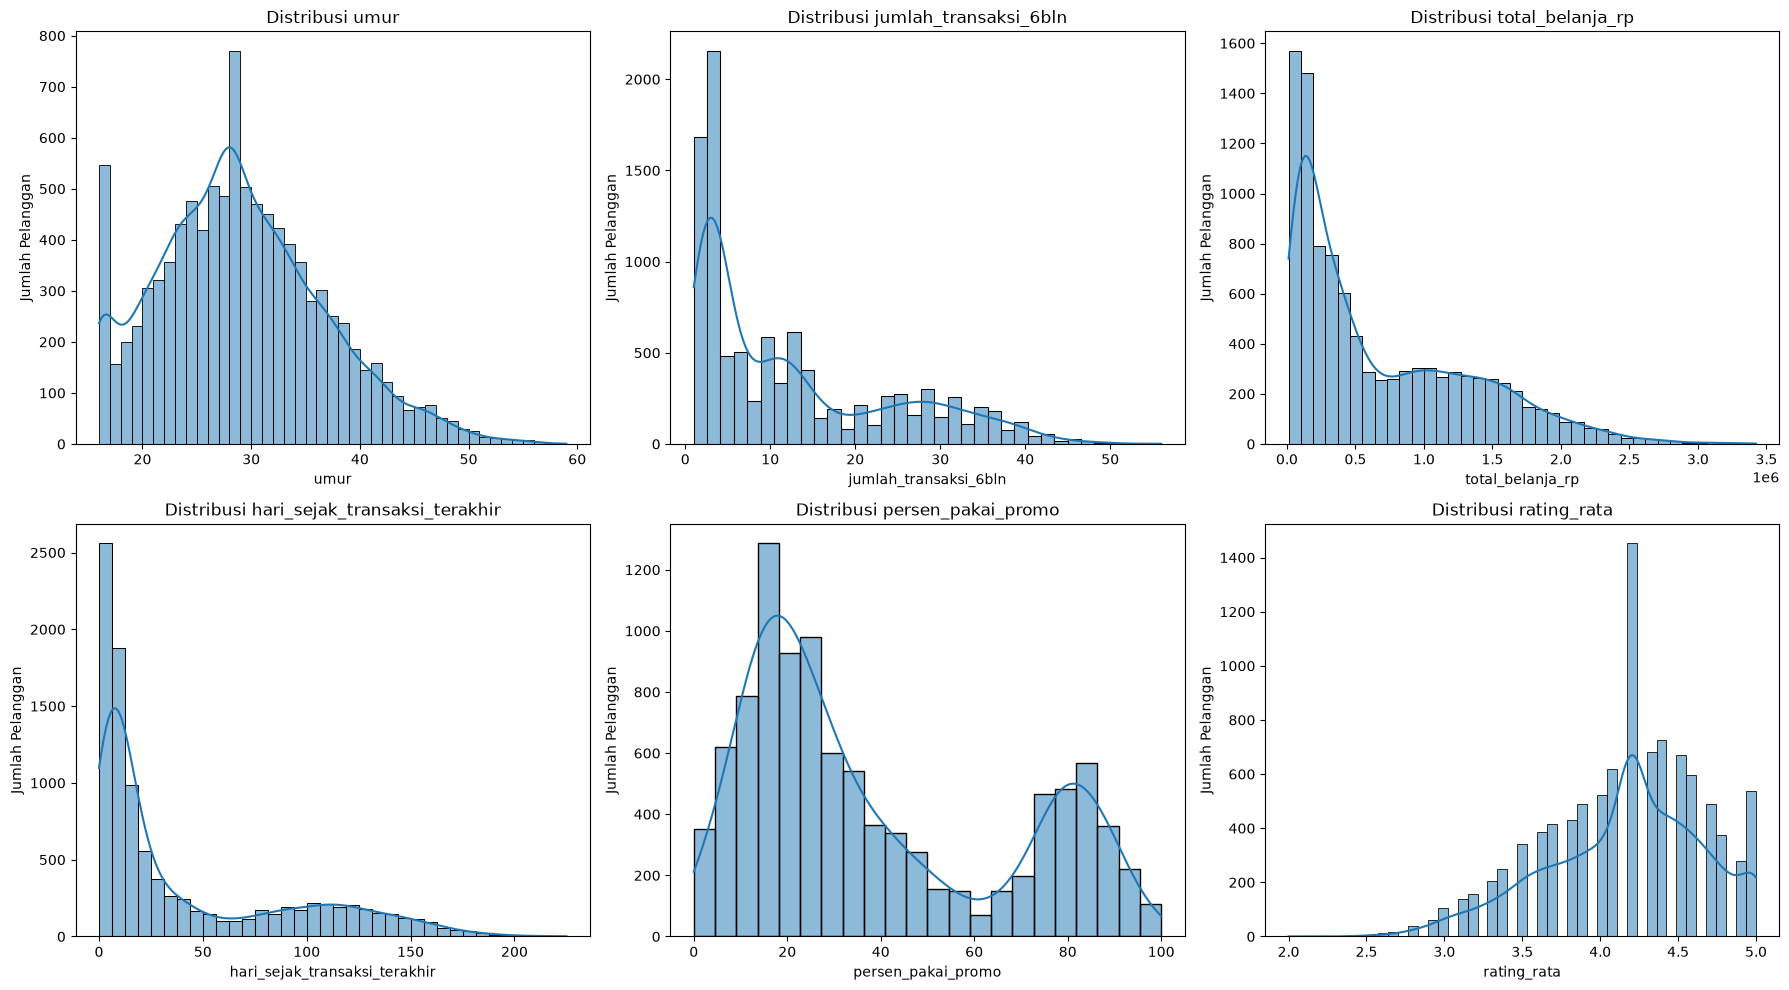

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat histogram untuk setiap fitur numerik
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for kolom, ax in zip(kolom_numerik, axes.flatten()):
    sns.histplot(
        data=df_clean,
        x=kolom,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribusi {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Jumlah Pelanggan")

plt.tight_layout()
plt.savefig(
    "../reports/figures/distribusi_fitur.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [32]:
kolom_kategorikal = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

for kolom in kolom_kategorikal:
    print(f"\n===== Distribusi {kolom} =====")
    print(df_clean[kolom].value_counts())
    print("\nPersentase:")
    print(
        (df_clean[kolom].value_counts(normalize=True) * 100)
        .round(2)
    )


===== Distribusi kecamatan =====
kecamatan
Buahbatu             1030
Cidadap              1018
Sumur Bandung         989
Arcamanik             984
Sukajadi              971
Bandung Wetan         969
Antapani              968
Lengkong              960
Coblong               934
Cibeunying Kidul      928
SUKAJADI               66
Bdg Wetan              55
Buah Batu              47
coblong                45
Cibeunying Kidul       36
Name: count, dtype: int64

Persentase:
kecamatan
Buahbatu             10.30
Cidadap              10.18
Sumur Bandung         9.89
Arcamanik             9.84
Sukajadi              9.71
Bandung Wetan         9.69
Antapani              9.68
Lengkong              9.60
Coblong               9.34
Cibeunying Kidul      9.28
SUKAJADI              0.66
Bdg Wetan             0.55
Buah Batu             0.47
coblong               0.45
Cibeunying Kidul      0.36
Name: proportion, dtype: float64

===== Distribusi channel_utama =====
channel_utama
toko          4603
gofood  

## **FEATURE ENGINEERING** ##

# Tahap 1 — Merapikan kategori dan menyiapkan fitur

In [38]:
# menyamakan penulisan nama kecamatan
# Rapikan spasi
df_clean["kecamatan"] = df_clean["kecamatan"].str.strip()

# Samakan nama kecamatan yang penulisannya berbeda
mapping_kecamatan = {
    "SUKAJADI": "Sukajadi",
    "Bdg Wetan": "Bandung Wetan",
    "Buah Batu": "Buahbatu",
    "coblong": "Coblong",
    "Cibeunying Kidul": "Cibeunying Kidul"
}

df_clean["kecamatan"] = df_clean["kecamatan"].replace(mapping_kecamatan)

# Cek hasil
print(df_clean["kecamatan"].value_counts())

kecamatan
Buahbatu            1077
Sukajadi            1037
Bandung Wetan       1024
Cidadap             1018
Sumur Bandung        989
Arcamanik            984
Coblong              979
Antapani             968
Cibeunying Kidul     964
Lengkong             960
Name: count, dtype: int64


In [39]:
# Membuat fitur lama bergabung
tanggal_acuan = pd.Timestamp("2026-06-30")

df_clean["lama_bergabung_hari"] = (
    tanggal_acuan - df_clean["tanggal_daftar"]
).dt.days

# Cek hasil
print(df_clean["lama_bergabung_hari"].describe())

count    10000.000000
mean       463.259300
std        250.824696
min         30.000000
25%        249.000000
50%        461.000000
75%        680.000000
max        899.000000
Name: lama_bergabung_hari, dtype: float64


In [40]:
# menetukan fitur untuk clustering
fitur_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

fitur_kategorikal = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

# Gabungkan fitur yang akan digunakan
df_fitur = df_clean[fitur_numerik + fitur_kategorikal].copy()

print("Jumlah baris dan kolom fitur:", df_fitur.shape)
display(df_fitur.head())

Jumlah baris dan kolom fitur: (10000, 11)


,umur,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,lama_bergabung_hari,kecamatan,channel_utama,metode_bayar,kategori_favorit
0,39.0,27,1480300,0,17,4.2,305,Buahbatu,toko,qris,roti
1,22.0,32,1289100,0,18,4.0,411,Buahbatu,shopeefood,ewallet,kopi
2,37.0,14,410500,0,74,4.3,745,Buahbatu,shopeefood,tunai,roti
3,31.0,41,1629500,0,29,4.2,208,Cibeunying Kidul,toko,qris,kopi
4,29.0,27,1308100,0,25,4.1,337,Arcamanik,toko,tunai,kopi


In [41]:
# Transformasi data dan encoding
import numpy as np
import pandas as pd

df_model = df_fitur.copy()

kolom_log = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir"
]

for kolom in kolom_log:
    df_model[kolom] = np.log1p(df_model[kolom])

# Ubah fitur kategorikal menjadi kolom angka (One-Hot Encoding)
df_model = pd.get_dummies(
    df_model,
    columns=fitur_kategorikal,
    dtype=int
)

print("Jumlah fitur setelah encoding:", df_model.shape[1])
display(df_model.head())

Jumlah fitur setelah encoding: 29


,umur,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,lama_bergabung_hari,kecamatan_Antapani,kecamatan_Arcamanik,kecamatan_Bandung Wetan,kecamatan_Buahbatu,kecamatan_Cibeunying Kidul,kecamatan_Cidadap,kecamatan_Coblong,kecamatan_Lengkong,kecamatan_Sukajadi,kecamatan_Sumur Bandung,channel_utama_gofood,channel_utama_grabfood,channel_utama_shopeefood,channel_utama_toko,metode_bayar_ewallet,metode_bayar_qris,metode_bayar_transfer,metode_bayar_tunai,kategori_favorit_kopi,kategori_favorit_kue_ulang_tahun,kategori_favorit_paket_snack,kategori_favorit_roti
0,39.0,3.332205,14.207756,0.0,17,4.2,305,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1
1,22.0,3.496508,14.069456,0.0,18,4.0,411,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0
2,37.0,2.708050,12.925134,0.0,74,4.3,745,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
3,31.0,3.737670,14.303784,0.0,29,4.2,208,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0
4,29.0,3.332205,14.084087,0.0,25,4.1,337,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0


In [42]:
# Scaling seluruh fitur 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_model)

print("Ukuran data setelah scaling:", X_scaled.shape)
print("Scaling berhasil!")

Ukuran data setelah scaling: (10000, 29)
Scaling berhasil!


# Tahap 2 — Mencari jumlah cluster terbaik (K)

In [59]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

# Membuat model K-Means
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Menghitung Silhouette Score
score_3000 = silhouette_score(
    X_scaled,
    labels,
    sample_size=3000,
    random_state=42
)

score_5000 = silhouette_score(
    X_scaled,
    labels,
    sample_size=5000,
    random_state=42
)

score_10000 = silhouette_score(
    X_scaled,
    labels
)

print("Silhouette Score 3.000 :", score_3000)
print("Silhouette Score 5.000 :", score_5000)
print("Silhouette Score 10.000:", score_10000)

Silhouette Score 3.000 : 0.20565152169132103
Silhouette Score 5.000 : 0.20817687819053135
Silhouette Score 10.000: 0.20954781324191404


In [56]:
# Menguji K dari 2 sampai 10
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hasil_silhouette = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Gunakan sampel 10.000 baris agar perhitungan bagus
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    hasil_silhouette.append({
        "K": k,
        "Silhouette Score": score
    })

    print(f"K = {k} | Silhouette Score = {score:.4f}")

K = 2 | Silhouette Score = 0.0817
K = 3 | Silhouette Score = 0.0749
K = 4 | Silhouette Score = 0.0832
K = 5 | Silhouette Score = 0.0889
K = 6 | Silhouette Score = 0.0895
K = 7 | Silhouette Score = 0.1025
K = 8 | Silhouette Score = 0.1402
K = 9 | Silhouette Score = 0.1881
K = 10 | Silhouette Score = 0.2095


In [60]:
# Membandingkan hasilnya dalam tabel
df_silhouette = pd.DataFrame(hasil_silhouette)

df_silhouette = df_silhouette.sort_values(
    by="Silhouette Score",
    ascending=False
).reset_index(drop=True)

display(df_silhouette)

k_terbaik = int(df_silhouette.loc[0, "K"])
score_terbaik = df_silhouette.loc[0, "Silhouette Score"]

print(f"K terbaik sementara: {k_terbaik}")
print(f"Silhouette Score: {score_terbaik:.4f}")

,K,Silhouette Score
0,10,0.209548
1,9,0.188055
2,8,0.140208
3,7,0.102517
4,6,0.089538
5,5,0.088918
6,4,0.083173
7,2,0.081689
8,3,0.074939


K terbaik sementara: 10
Silhouette Score: 0.2095


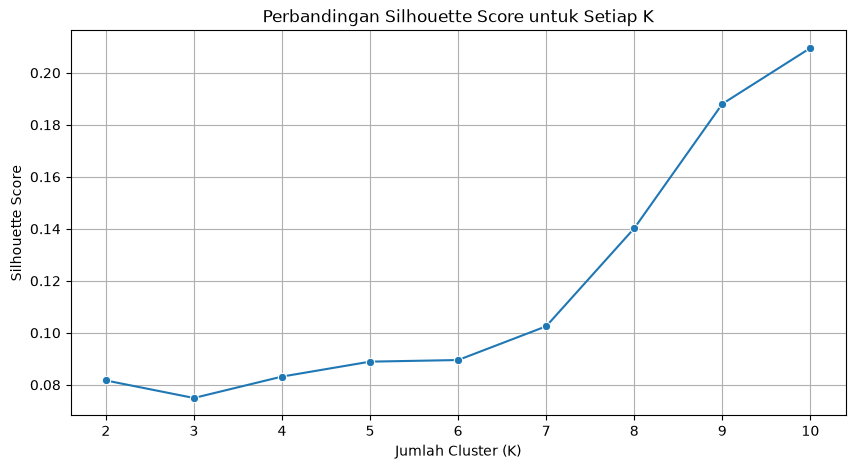

In [ ]:
# Visualisasi perbandingan Silhouette Score
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df_silhouette.sort_values("K"),
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Perbandingan Silhouette Score untuk Setiap K")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../reports/figures/silhouette_per_k.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Tahap 3 — Perluas percobaan K dari 2 sampai 15

In [62]:
# Uji K 2 sampai 20

hasil_silhouette_lanjutan = []

for k in range(2, 21):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    # Cek ukuran cluster
    jumlah_anggota = pd.Series(labels).value_counts()

    hasil_silhouette_lanjutan.append({
        "K": k,
        "Silhouette Score": score,
        "Cluster Terkecil": jumlah_anggota.min(),
        "Cluster Terbesar": jumlah_anggota.max()
    })

    print(
        f"K={k} | Silhouette={score:.4f} | "
        f"Cluster terkecil={jumlah_anggota.min()}"
    )

K=2 | Silhouette=0.0817 | Cluster terkecil=3131
K=3 | Silhouette=0.0749 | Cluster terkecil=2527
K=4 | Silhouette=0.0832 | Cluster terkecil=1665
K=5 | Silhouette=0.0889 | Cluster terkecil=962
K=6 | Silhouette=0.0895 | Cluster terkecil=1152
K=7 | Silhouette=0.1025 | Cluster terkecil=968
K=8 | Silhouette=0.1402 | Cluster terkecil=960
K=9 | Silhouette=0.1881 | Cluster terkecil=960
K=10 | Silhouette=0.2095 | Cluster terkecil=960
K=11 | Silhouette=0.1744 | Cluster terkecil=312
K=12 | Silhouette=0.1800 | Cluster terkecil=635
K=13 | Silhouette=0.1531 | Cluster terkecil=355
K=14 | Silhouette=0.1511 | Cluster terkecil=303
K=15 | Silhouette=0.1406 | Cluster terkecil=306
K=16 | Silhouette=0.1375 | Cluster terkecil=303
K=17 | Silhouette=0.1407 | Cluster terkecil=302
K=18 | Silhouette=0.1309 | Cluster terkecil=302
K=19 | Silhouette=0.1267 | Cluster terkecil=304
K=20 | Silhouette=0.1269 | Cluster terkecil=279


In [63]:
# Menampilkan hasil perbandingan
df_perbandingan = pd.DataFrame(hasil_silhouette_lanjutan)

display(
    df_perbandingan.sort_values(
        by="Silhouette Score",
        ascending=False
    ).reset_index(drop=True)
)

,K,Silhouette Score,Cluster Terkecil,Cluster Terbesar
0,10,0.209548,960,1077
1,9,0.188055,960,1953
2,12,0.180040,635,919
3,11,0.174397,312,1077
4,13,0.153092,355,921
5,14,0.151052,303,922
6,17,0.140681,302,868
7,15,0.140590,306,953
8,8,0.140208,960,2784
9,16,0.137478,303,897


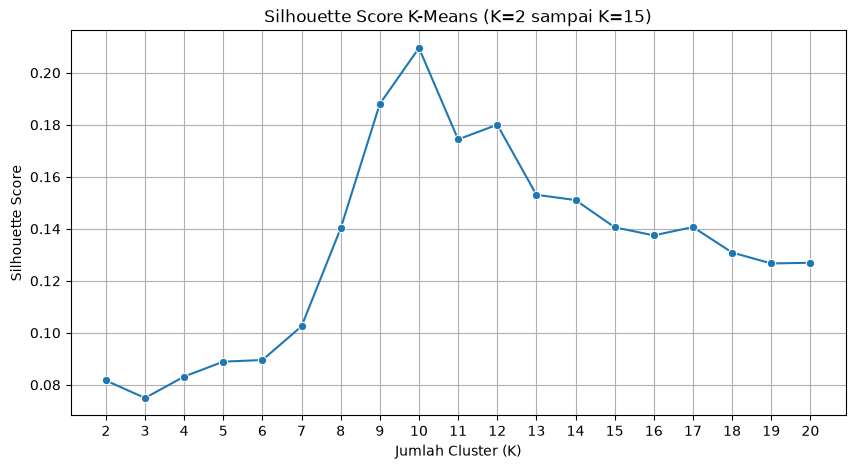

In [ ]:
# Memvisualisaikan hasil K 2 sampai 20
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df_perbandingan,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score K-Means (K=2 sampai K=15)")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 21))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../reports/figures/silhouette_k2_sampai_k15.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
# Memeriksa ukuran cluster dari kandidat dengan skor tertinggi
k_kandidat = int(
    df_perbandingan.loc[
        df_perbandingan["Silhouette Score"].idxmax(),
        "K"
    ]
)

model_kandidat = KMeans(
    n_clusters=k_kandidat,
    random_state=42,
    n_init=10
)

label_kandidat = model_kandidat.fit_predict(X_scaled)

print("K kandidat:", k_kandidat)
print("\nJumlah pelanggan per cluster:")
print(
    pd.Series(label_kandidat)
    .value_counts()
    .sort_index()
)

K kandidat: 10

Jumlah pelanggan per cluster:
0    1077
1     964
2     968
3     960
4    1024
5     989
6    1018
7    1037
8     979
9     984
Name: count, dtype: int64


In [66]:
# Membuat model K-Means final
# Melatih ulang K-Means dengan K=10 menggunakan seluruh data yang sudah diproses
k_final = 10

model_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

label_final = model_final.fit_predict(X_scaled)

# Salin data asli, lalu tambahkan label cluster
df_segmentasi = df_clean.copy()
df_segmentasi["cluster"] = label_final

print("Model final berhasil dibuat!")
print("Jumlah pelanggan:", len(df_segmentasi))
print("Jumlah cluster:", df_segmentasi["cluster"].nunique())

Model final berhasil dibuat!
Jumlah pelanggan: 10000
Jumlah cluster: 10


In [67]:
# Melihat jumlah dan persentase pelanggan setiap cluster
distribusi_cluster = (
    df_segmentasi["cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="jumlah_pelanggan")
)

distribusi_cluster["persentase"] = (
    distribusi_cluster["jumlah_pelanggan"] /
    len(df_segmentasi) * 100
).round(2)

display(distribusi_cluster)

,jumlah_pelanggan,persentase
cluster,,
0,1077,10.77
1,964,9.64
2,968,9.68
3,960,9.60
4,1024,10.24
5,989,9.89
6,1018,10.18
7,1037,10.37
8,979,9.79


In [68]:
# Membuat profil numerik setiap cluster
kolom_profil_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

profil_numerik = df_segmentasi.groupby("cluster")[
    kolom_profil_numerik
].agg(["mean", "median"]).round(2)

display(profil_numerik)

umur        jumlah_transaksi_6bln        total_belanja_rp            \
          mean median                  mean median             mean    median   
cluster                                                                         
0        29.12   28.0                 12.24    8.0        695785.52  432000.0   
1        29.15   28.0                 13.10    8.0        719560.17  451700.0   
2        28.83   28.0                 12.56    7.0        718628.20  452350.0   
3        28.87   28.0                 11.96    8.0        680414.06  418750.0   
4        28.54   28.0                 12.74    9.0        678597.46  415550.0   
5        28.56   28.0                 12.34    8.0        656445.90  407700.0   
6        28.62   28.0                 13.05   10.0        707158.94  440200.0   
7        29.05   28.0                 12.20    8.0        690866.54  426100.0   
8        28.80   28.0                 12.50    8.0        675790.81  402700.0   
9        29.17   28.0                 12.68    8.0        714671.14  433550.0   

        hari_sejak_transaksi_terakhir        persen_pakai_promo         \
                                 mean median               mean median   
cluster                                                                  
0                               41.01   16.0              38.97   28.0   
1                               40.96   14.0              36.61   27.0   
2                               42.71   16.5              37.49   27.0   
3                               44.22   17.0              38.15   28.0   
4                               40.66   14.0              39.16   28.0   
5                               43.70   17.0              38.75   27.0   
6                               39.20   15.0              38.62   27.5   
7                               41.89   16.0              38.16   28.0   
8                               41.94   15.0              40.53   30.0   
9                               41.53   16.0              38.25   27.0   

        rating_rata        lama_bergabung_hari         
               mean median                mean median  
cluster                                                
0              4.16    4.2              460.52  460.0  
1              4.16    4.2              467.54  465.5  
2              4.14    4.2              481.67  475.5  
3              4.14    4.2              474.86  483.5  
4              4.16    4.2              467.31  474.0  
5              4.13    4.2              451.11  430.0  
6              4.19    4.2              456.18  453.0  
7              4.17    4.2              458.38  448.0  
8              4.15    4.2              453.28  449.0  
9              4.17    4.2              463.02  456.5

In [69]:
# Melihat karakteristik kategorikal setiap cluster
kolom_profil_kategorikal = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

profil_kategorikal = df_segmentasi.groupby("cluster")[
    kolom_profil_kategorikal
].agg(lambda x: x.mode().iloc[0])

display(profil_kategorikal)

,kecamatan,channel_utama,metode_bayar,kategori_favorit
cluster,,,,
0,Buahbatu,toko,qris,kopi
1,Cibeunying Kidul,toko,qris,kopi
2,Antapani,toko,qris,kopi
3,Lengkong,toko,qris,kopi
4,Bandung Wetan,toko,qris,kopi
5,Sumur Bandung,toko,qris,kopi
6,Cidadap,toko,qris,kopi
7,Sukajadi,toko,qris,kopi
8,Coblong,toko,qris,kopi


In [70]:
# Melihat persentase kategori dalam setiap cluster
for kolom in kolom_profil_kategorikal:
    print(f"\n===== {kolom.upper()} PER CLUSTER (%) =====")

    tabel = pd.crosstab(
        df_segmentasi["cluster"],
        df_segmentasi[kolom],
        normalize="index"
    ) * 100

    display(tabel.round(1))


===== KECAMATAN PER CLUSTER (%) =====


kecamatan,Antapani,Arcamanik,Bandung Wetan,Buahbatu,Cibeunying Kidul,Cidadap,Coblong,Lengkong,Sukajadi,Sumur Bandung
cluster,,,,,,,,,,
0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0
4,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
6,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0



===== CHANNEL_UTAMA PER CLUSTER (%) =====


channel_utama,gofood,grabfood,shopeefood,toko
cluster,,,,
0,22.7,16.2,16.9,44.3
1,20.9,16.3,14.2,48.7
2,18.3,16.6,17.7,47.4
3,21.5,13.8,17.1,47.7
4,22.9,16.5,15.8,44.8
5,20.6,15.3,17.3,46.8
6,18.3,17.1,16.9,47.7
7,21.5,14.3,18.9,45.3
8,24.1,16.1,17.0,42.8



===== METODE_BAYAR PER CLUSTER (%) =====


metode_bayar,ewallet,qris,transfer,tunai
cluster,,,,
0,18.3,45.8,9.4,26.6
1,20.2,45.5,10.3,24.0
2,19.9,45.0,9.6,25.4
3,18.6,44.4,11.0,25.9
4,20.0,45.2,11.5,23.2
5,18.6,47.5,9.6,24.3
6,17.6,44.0,12.8,25.6
7,23.5,42.5,9.4,24.6
8,18.4,47.7,9.2,24.7



===== KATEGORI_FAVORIT PER CLUSTER (%) =====


kategori_favorit,kopi,kue_ulang_tahun,paket_snack,roti
cluster,,,,
0,39.8,13.3,12.2,34.7
1,40.4,12.9,10.8,36.0
2,40.2,12.1,13.8,33.9
3,40.3,12.6,12.5,34.6
4,40.7,11.4,11.5,36.3
5,42.8,12.6,10.8,33.8
6,42.7,10.5,12.6,34.2
7,41.8,13.6,12.5,32.1
8,42.2,12.4,10.1,35.3


# Memperbaiki fitur clustering dg menghilangkan kecamatan

In [71]:
# Menentukan ulang fitur
fitur_numerik = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

fitur_kategorikal = [
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

df_fitur_baru = df_clean[
    fitur_numerik + fitur_kategorikal
].copy()

print("Ukuran fitur:", df_fitur_baru.shape)
display(df_fitur_baru.head())

Ukuran fitur: (10000, 10)


,umur,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,lama_bergabung_hari,channel_utama,metode_bayar,kategori_favorit
0,39.0,27,1480300,0,17,4.2,305,toko,qris,roti
1,22.0,32,1289100,0,18,4.0,411,shopeefood,ewallet,kopi
2,37.0,14,410500,0,74,4.3,745,shopeefood,tunai,roti
3,31.0,41,1629500,0,29,4.2,208,toko,qris,kopi
4,29.0,27,1308100,0,25,4.1,337,toko,tunai,kopi


In [73]:
# Transformasi dan encoding ulang
df_model_baru = df_fitur_baru.copy()

kolom_log = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir"
]

for kolom in kolom_log:
    df_model_baru[kolom] = np.log1p(
        df_model_baru[kolom]
    )

df_model_baru = pd.get_dummies(
    df_model_baru,
    columns=fitur_kategorikal,
    dtype=int
)

print("Jumlah fitur setelah encoding:", df_model_baru.shape[1])
display(df_model_baru.head())

Jumlah fitur setelah encoding: 19


,umur,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,lama_bergabung_hari,channel_utama_gofood,channel_utama_grabfood,channel_utama_shopeefood,channel_utama_toko,metode_bayar_ewallet,metode_bayar_qris,metode_bayar_transfer,metode_bayar_tunai,kategori_favorit_kopi,kategori_favorit_kue_ulang_tahun,kategori_favorit_paket_snack,kategori_favorit_roti
0,39.0,3.332205,14.207756,0.0,17,4.2,305,0,0,0,1,0,1,0,0,0,0,0,1
1,22.0,3.496508,14.069456,0.0,18,4.0,411,0,0,1,0,1,0,0,0,1,0,0,0
2,37.0,2.708050,12.925134,0.0,74,4.3,745,0,0,1,0,0,0,0,1,0,0,0,1
3,31.0,3.737670,14.303784,0.0,29,4.2,208,0,0,0,1,0,1,0,0,1,0,0,0
4,29.0,3.332205,14.084087,0.0,25,4.1,337,0,0,0,1,0,0,0,1,1,0,0,0


In [74]:
# Scaling ulang
scaler_baru = StandardScaler()

X_scaled_baru = scaler_baru.fit_transform(
    df_model_baru
)

print("Ukuran data:", X_scaled_baru.shape)
print("Scaling berhasil!")

Ukuran data: (10000, 19)
Scaling berhasil!


In [75]:
# Menguji K-Means dari 2 sampai 20
hasil_silhouette_baru = []

for k in range(2, 21):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled_baru)

    score = silhouette_score(
        X_scaled_baru,
        labels
    )

    ukuran_cluster = pd.Series(labels).value_counts()

    hasil_silhouette_baru.append({
        "K": k,
        "Silhouette Score": score,
        "Cluster Terkecil": ukuran_cluster.min(),
        "Cluster Terbesar": ukuran_cluster.max()
    })

    print(f"K={k} | Silhouette Score={score:.6f}")

K=2 | Silhouette Score=0.125434
K=3 | Silhouette Score=0.120190
K=4 | Silhouette Score=0.136062
K=5 | Silhouette Score=0.151912
K=6 | Silhouette Score=0.139083
K=7 | Silhouette Score=0.132853
K=8 | Silhouette Score=0.165773
K=9 | Silhouette Score=0.143188
K=10 | Silhouette Score=0.140990
K=11 | Silhouette Score=0.145190
K=12 | Silhouette Score=0.143979
K=13 | Silhouette Score=0.161950
K=14 | Silhouette Score=0.156641
K=15 | Silhouette Score=0.158593
K=16 | Silhouette Score=0.161274
K=17 | Silhouette Score=0.161457
K=18 | Silhouette Score=0.147825
K=19 | Silhouette Score=0.151341
K=20 | Silhouette Score=0.160563


In [76]:
# Membandingkan hasil K
df_perbandingan_baru = pd.DataFrame(
    hasil_silhouette_baru
)

df_perbandingan_baru = df_perbandingan_baru.sort_values(
    by="Silhouette Score",
    ascending=False
).reset_index(drop=True)

display(df_perbandingan_baru)

k_terbaik_baru = int(
    df_perbandingan_baru.loc[0, "K"]
)

print("K terbaik baru:", k_terbaik_baru)
print(
    "Silhouette Score terbaik:",
    round(
        df_perbandingan_baru.loc[0, "Silhouette Score"],
        6
    )
)

,K,Silhouette Score,Cluster Terkecil,Cluster Terbesar
0,8,0.165773,845,2266
1,13,0.161950,482,1084
2,17,0.161457,314,948
3,16,0.161274,288,965
4,20,0.160563,216,897
5,15,0.158593,280,956
6,14,0.156641,495,1084
7,5,0.151912,1188,2844
8,19,0.151341,257,858
9,18,0.147825,261,879


K terbaik baru: 8
Silhouette Score terbaik: 0.165773


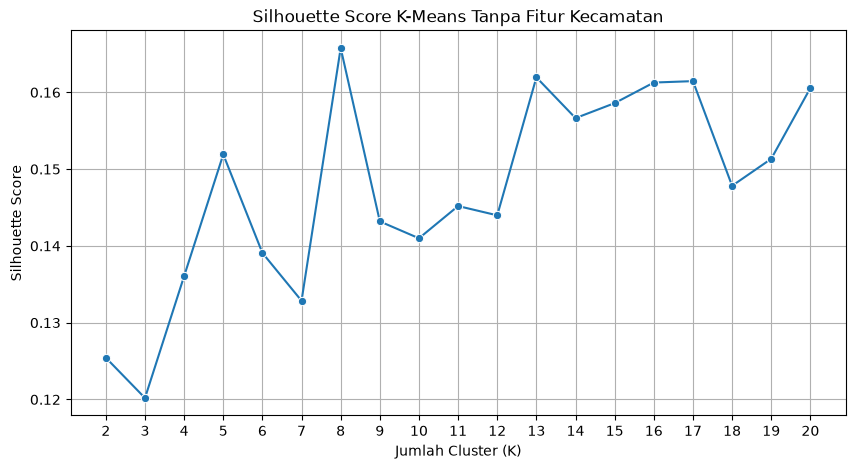

In [ ]:
# Grafik Silhouette Score yang baru
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df_perbandingan_baru.sort_values("K"),
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score K-Means Tanpa Fitur Kecamatan")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 21))
plt.grid(True)
plt.tight_layout()
plt.savefig(
    "../reports/silhouette_tanpa_kecamatan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Nyari 4 meodel

## Tahap 1 — Menyiapkan keempat model

In [ ]:
# Definisi fitur setiap model
# Fitur numerik
numerik_7 = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

# Fitur numerik tanpa umur
numerik_6 = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

# Fitur kategorikal
kategorikal_4 = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

kategorikal_3 = [
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

# Definisi empat model
konfigurasi_model = {
    "Model 1": {
        "numerik": numerik_7,
        "kategorikal": kategorikal_4
    },
    "Model 2": {
        "numerik": numerik_7,
        "kategorikal": kategorikal_3
    },
    "Model 3": {
        "numerik": numerik_6,
        "kategorikal": kategorikal_3
    },
    "Model 4": {
        "numerik": numerik_6,
        "kategorikal": []
    }
}

print("Konfigurasi 4 model berhasil dibuat!")

Konfigurasi 4 model berhasil dibuat!


In [80]:
# Preprocessing masing-masing model
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Kolom yang akan ditransformasi log
kolom_log = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir"
]

data_model = {}

for nama_model, konfigurasi in konfigurasi_model.items():

    fitur_num = konfigurasi["numerik"]
    fitur_cat = konfigurasi["kategorikal"]

    # Ambil fitur
    df_temp = df_clean[fitur_num + fitur_cat].copy()

    # Transformasi log untuk fitur yang miring ke kanan
    for kolom in kolom_log:
        if kolom in fitur_num:
            df_temp[kolom] = np.log1p(df_temp[kolom])

    # One-Hot Encoding
    if fitur_cat:
        df_temp = pd.get_dummies(
            df_temp,
            columns=fitur_cat,
            dtype=int
        )

    # Standard Scaling
    scaler = StandardScaler()
    X_scaled_temp = scaler.fit_transform(df_temp)

    # Simpan hasil preprocessing
    data_model[nama_model] = {
        "X": X_scaled_temp,
        "scaler": scaler,
        "kolom_fitur": df_temp.columns.tolist()
    }

    print(
        f"{nama_model}: "
        f"{X_scaled_temp.shape[0]} data, "
        f"{X_scaled_temp.shape[1]} fitur"
    )

Model 1: 10000 data, 29 fitur
Model 2: 10000 data, 19 fitur
Model 3: 10000 data, 18 fitur
Model 4: 10000 data, 6 fitur


## Tahap 2 — Mencari K terbaik untuk masing-masing model

In [81]:
# Eksperimen K-Means untuk empat model
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Gunakan sampel baris yang sama untuk seluruh model
np.random.seed(42)

indeks_sampel = np.random.choice(
    len(df_clean),
    size=3000,
    replace=False
)

hasil_semua_model = []

# Simpan model dan label terbaik sementara
model_kandidat = {}

for nama_model, data in data_model.items():

    print(f"\n===== {nama_model} =====")

    X = data["X"]

    skor_model = []

    for k in range(2, 21):

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = kmeans.fit_predict(X)

        # Silhouette Score pada sampel yang sama
        score = silhouette_score(
            X[indeks_sampel],
            labels[indeks_sampel]
        )

        skor_model.append({
            "Model": nama_model,
            "K": k,
            "Silhouette Score": score
        })

        print(f"K={k} | Silhouette Score={score:.6f}")

    # Simpan seluruh hasil
    hasil_semua_model.extend(skor_model)

    # Cari K terbaik sementara
    df_skor = pd.DataFrame(skor_model)

    baris_terbaik = df_skor.loc[
        df_skor["Silhouette Score"].idxmax()
    ]

    k_terbaik = int(baris_terbaik["K"])

    model_kandidat[nama_model] = {
        "K": k_terbaik
    }

    print(
        f"K terbaik sementara {nama_model}: "
        f"{k_terbaik}"
    )


===== Model 1 =====
K=2 | Silhouette Score=0.082287
K=3 | Silhouette Score=0.074226
K=4 | Silhouette Score=0.082344
K=5 | Silhouette Score=0.087673
K=6 | Silhouette Score=0.088852
K=7 | Silhouette Score=0.101824
K=8 | Silhouette Score=0.138758
K=9 | Silhouette Score=0.184445
K=10 | Silhouette Score=0.205652
K=11 | Silhouette Score=0.173854
K=12 | Silhouette Score=0.177627
K=13 | Silhouette Score=0.152037
K=14 | Silhouette Score=0.150189
K=15 | Silhouette Score=0.139569
K=16 | Silhouette Score=0.136858
K=17 | Silhouette Score=0.139377
K=18 | Silhouette Score=0.129618
K=19 | Silhouette Score=0.126492
K=20 | Silhouette Score=0.125900
K terbaik sementara Model 1: 10

===== Model 2 =====
K=2 | Silhouette Score=0.125849
K=3 | Silhouette Score=0.118740
K=4 | Silhouette Score=0.134465
K=5 | Silhouette Score=0.150437
K=6 | Silhouette Score=0.137867
K=7 | Silhouette Score=0.131703
K=8 | Silhouette Score=0.164964
K=9 | Silhouette Score=0.140832
K=10 | Silhouette Score=0.140686
K=11 | Silhouette 

In [82]:
# Membandingkan K terbaik dari empat model
df_hasil_semua = pd.DataFrame(hasil_semua_model)

# Ambil hasil terbaik masing-masing model
df_k_terbaik = (
    df_hasil_semua
    .sort_values("Silhouette Score", ascending=False)
    .groupby("Model")
    .head(1)
    .sort_values("Model")
    .reset_index(drop=True)
)

display(df_k_terbaik)

,Model,K,Silhouette Score
0,Model 1,10,0.205652
1,Model 2,8,0.164964
2,Model 3,20,0.177680
3,Model 4,4,0.372964


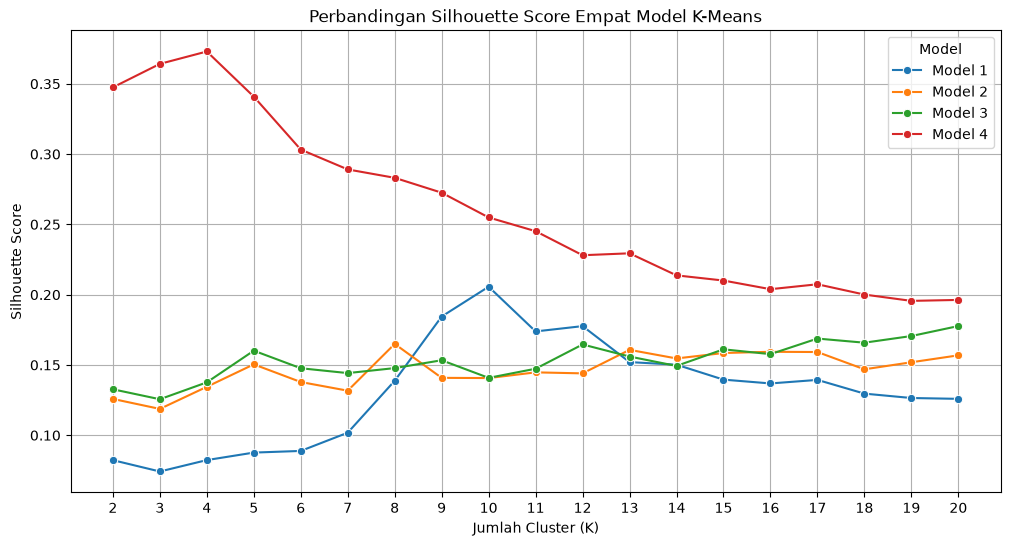

In [ ]:
# Grafik perbandingan seluruh model
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_hasil_semua,
    x="K",
    y="Silhouette Score",
    hue="Model",
    marker="o"
)

plt.title("Perbandingan Silhouette Score Empat Model K-Means")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 21))
plt.grid(True)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "../reports/figures/perbandingan_empat_model.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Tahap 3 — Evaluasi ulang menggunakan seluruh 10.000 data

In [85]:
# menghitung sampel untuk Silhouette Score
print(f"Jumlah sampel: {X.shape[0]}")

score_full = silhouette_score(X, labels)

Jumlah sampel: 10000


In [ ]:
# Hitung Silhouette Score seluruh data
hasil_evaluasi_final = []

for nama_model, data in data_model.items():

    X = data["X"]
    k = model_kandidat[nama_model]["K"]

    # Latih ulang K-Means dengan K terbaik sementara
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    # Hitung silhouette menggunakan seluruh data
    score_full = silhouette_score(X, labels)

    # Hitung ukuran cluster
    ukuran = pd.Series(labels).value_counts()

    hasil_evaluasi_final.append({
        "Model": nama_model,
        "K Terbaik": k,
        "Silhouette Score Full": score_full,
        "Cluster Terkecil": ukuran.min(),
        "Cluster Terbesar": ukuran.max()
    })

    # Simpan hasil model
    model_kandidat[nama_model]["model"] = kmeans
    model_kandidat[nama_model]["labels"] = labels
    model_kandidat[nama_model]["score_full"] = score_full

    print(
        f"{nama_model} | K={k} | "
        f" Score Silhouette Full = {score_full:.6f}"
    )

Model 1 | K=10 | Silhouette Full=0.209548
Model 2 | K=8 | Silhouette Full=0.165773
Model 3 | K=20 | Silhouette Full=0.180373
Model 4 | K=4 | Silhouette Full=0.369635


In [86]:
# Tabel perbandingan akhir
df_perbandingan_model = pd.DataFrame(
    hasil_evaluasi_final
)

df_perbandingan_model = df_perbandingan_model.sort_values(
    by="Silhouette Score Full",
    ascending=False
).reset_index(drop=True)

display(df_perbandingan_model)

# Model dengan skor tertinggi
model_terpilih = df_perbandingan_model.iloc[0]["Model"]

print("Model dengan Silhouette Score tertinggi:", model_terpilih)

,Model,K Terbaik,Silhouette Score Full,Cluster Terkecil,Cluster Terbesar
0,Model 4,4,0.369635,1514,3023
1,Model 1,10,0.209548,960,1077
2,Model 3,20,0.180373,281,753
3,Model 2,8,0.165773,845,2266


Model dengan Silhouette Score tertinggi: Model 4


## Tahap 4 — Menetapkan model final

In [87]:
# Simpan hasil segmentasi model terpilih
hasil_model_final = model_kandidat[model_terpilih]

k_final = hasil_model_final["K"]
labels_final = hasil_model_final["labels"]

df_segmentasi_final = df_clean.copy()
df_segmentasi_final["cluster"] = labels_final

print("Model final:", model_terpilih)
print("Jumlah cluster:", k_final)

print("\nJumlah pelanggan per cluster:")
print(
    df_segmentasi_final["cluster"]
    .value_counts()
    .sort_index()
)

Model final: Model 4
Jumlah cluster: 4

Jumlah pelanggan per cluster:
cluster
0    2497
1    2966
2    3023
3    1514
Name: count, dtype: int64


# Tahap evaluasi tambahan untuk keempat model

In [88]:
# Menghitung Davies-Bouldin dan Calinski-Harabasz
from sklearn.metrics import (
    davies_bouldin_score,
    calinski_harabasz_score
)

hasil_metrik_lengkap = []

for nama_model, data in data_model.items():

    X = data["X"]
    hasil = model_kandidat[nama_model]
    labels = hasil["labels"]

    db_score = davies_bouldin_score(X, labels)
    ch_score = calinski_harabasz_score(X, labels)

    ukuran = pd.Series(labels).value_counts()

    hasil_metrik_lengkap.append({
        "Model": nama_model,
        "K": hasil["K"],
        "Silhouette": hasil["score_full"],
        "Davies-Bouldin": db_score,
        "Calinski-Harabasz": ch_score,
        "Cluster Terkecil": ukuran.min(),
        "Cluster Terbesar": ukuran.max()
    })

df_metrik_lengkap = pd.DataFrame(hasil_metrik_lengkap)

display(
    df_metrik_lengkap.sort_values(
        "Silhouette",
        ascending=False
    ).reset_index(drop=True)
)

,Model,K,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster Terkecil,Cluster Terbesar
0,Model 4,4,0.369635,1.128902,5660.667096,1514,3023
1,Model 1,10,0.209548,1.859416,585.927814,960,1077
2,Model 3,20,0.180373,1.760675,682.316639,281,753
3,Model 2,8,0.165773,1.912506,927.898040,845,2266


In [89]:
# Melihat distribusi ukuran cluster seluruh model
hasil_ukuran_cluster = []

for nama_model, hasil in model_kandidat.items():

    labels = hasil["labels"]

    jumlah = pd.Series(labels).value_counts().sort_index()

    for cluster, banyak in jumlah.items():
        hasil_ukuran_cluster.append({
            "Model": nama_model,
            "Cluster": cluster,
            "Jumlah Pelanggan": banyak,
            "Persentase": banyak / len(df_clean) * 100
        })

df_ukuran_cluster = pd.DataFrame(hasil_ukuran_cluster)

display(
    df_ukuran_cluster.round(2)
)

,Model,Cluster,Jumlah Pelanggan,Persentase
0,Model 1,0,1077,10.77
1,Model 1,1,964,9.64
2,Model 1,2,968,9.68
3,Model 1,3,960,9.60
4,Model 1,4,1024,10.24
5,Model 1,5,989,9.89
6,Model 1,6,1018,10.18
7,Model 1,7,1037,10.37
8,Model 1,8,979,9.79
9,Model 1,9,984,9.84


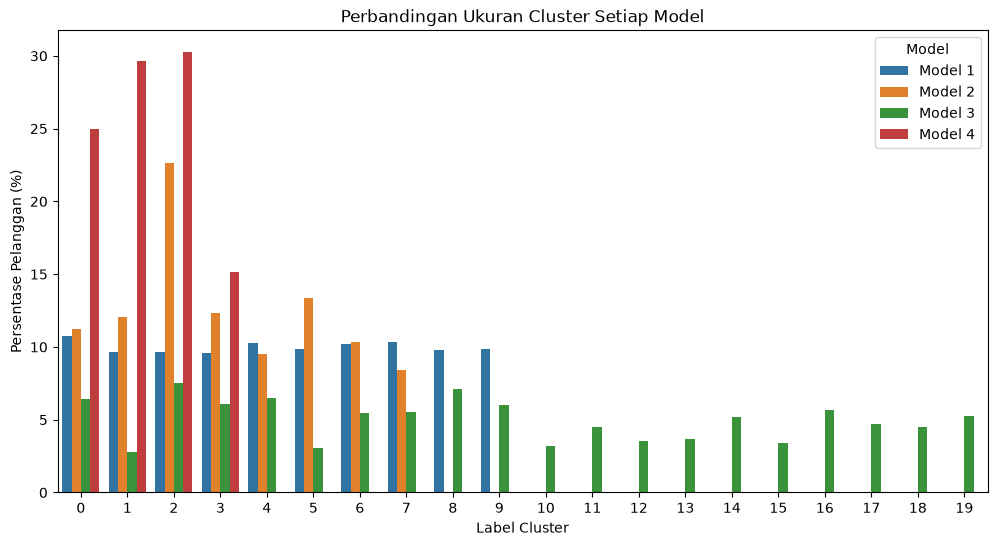

In [ ]:
# Visualisasi ukuran cluster
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_ukuran_cluster,
    x="Cluster",
    y="Persentase",
    hue="Model"
)

plt.title("Perbandingan Ukuran Cluster Setiap Model")
plt.xlabel("Label Cluster")
plt.ylabel("Persentase Pelanggan (%)")
plt.tight_layout()

plt.savefig(
    "../reports/figures/ukuran_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Melihat karakteristik kategorikal setiap cluster
kolom_profil_kategorikal = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

profil_kategorikal = df_segmentasi.groupby("cluster")[
    kolom_profil_kategorikal
].agg(lambda x: x.mode().iloc[0])

display(profil_kategorikal)

,kecamatan,channel_utama,metode_bayar,kategori_favorit
cluster,,,,
0,Buahbatu,toko,qris,kopi
1,Cibeunying Kidul,toko,qris,kopi
2,Antapani,toko,qris,kopi
3,Lengkong,toko,qris,kopi
4,Bandung Wetan,toko,qris,kopi
5,Sumur Bandung,toko,qris,kopi
6,Cidadap,toko,qris,kopi
7,Sukajadi,toko,qris,kopi
8,Coblong,toko,qris,kopi


# prediksi model 4 yang dipakai yaa

In [91]:
# Membuat hasil segmentasi Model 4
df_segmentasi_model4 = df_clean.copy()

df_segmentasi_model4["cluster"] = (
    model_kandidat["Model 4"]["labels"]
)

print("K Model 4:", model_kandidat["Model 4"]["K"])

print(
    df_segmentasi_model4["cluster"]
    .value_counts()
    .sort_index()
)

K Model 4: 4
cluster
0    2497
1    2966
2    3023
3    1514
Name: count, dtype: int64


In [92]:
# Profil numerik tiap cluster
kolom_profil = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

profil_model4 = df_segmentasi_model4.groupby("cluster")[
    kolom_profil
].agg(["mean", "median"]).round(2)

display(profil_model4)

umur        jumlah_transaksi_6bln        total_belanja_rp  \
          mean median                  mean median             mean   
cluster                                                               
0        26.98   27.0                 10.93   11.0        348541.33   
1        27.43   27.0                  2.56    3.0        107158.09   
2        27.39   28.0                 27.88   28.0       1353954.09   
3        37.78   38.0                  4.10    4.0       1093768.56   

                   hari_sejak_transaksi_terakhir        persen_pakai_promo  \
            median                          mean median               mean   
cluster                                                                      
0         337800.0                         12.20   12.0              81.54   
1          98200.0                        109.61  110.0              34.64   
2        1313000.0                          5.15    5.0              19.66   
3        1021300.0                         30.66   30.0              12.56   

               rating_rata        lama_bergabung_hari         
        median        mean median                mean median  
cluster                                                       
0         82.0        4.37    4.4              462.82  463.0  
1         35.0        3.64    3.6              456.09  448.5  
2         20.0        4.38    4.4              467.00  465.0  
3         12.0        4.38    4.4              470.58  475.0

In [93]:
# Profil kategorikal tiap cluster
kolom_kategorikal = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

profil_kategori_model4 = df_segmentasi_model4.groupby("cluster")[
    kolom_kategorikal
].agg(lambda x: x.mode().iloc[0])

display(profil_kategori_model4)

,kecamatan,channel_utama,metode_bayar,kategori_favorit
cluster,,,,
0,Buahbatu,gofood,qris,roti
1,Sumur Bandung,toko,qris,kopi
2,Cidadap,toko,qris,kopi
3,Sukajadi,toko,qris,kue_ulang_tahun


In [94]:
# Persentase kategori dalam setiap cluster
for kolom in kolom_kategorikal:

    print(f"\n===== {kolom.upper()} PER CLUSTER (%) =====")

    tabel = pd.crosstab(
        df_segmentasi_model4["cluster"],
        df_segmentasi_model4[kolom],
        normalize="index"
    ) * 100

    display(tabel.round(1))


===== KECAMATAN PER CLUSTER (%) =====


kecamatan,Antapani,Arcamanik,Bandung Wetan,Buahbatu,Cibeunying Kidul,Cidadap,Coblong,Lengkong,Sukajadi,Sumur Bandung
cluster,,,,,,,,,,
0,9.0,9.9,11.0,11.1,8.6,10.5,10.8,9.1,10.3,9.8
1,9.7,9.7,9.9,10.5,9.6,9.5,10.1,10.2,10.1,10.6
2,9.8,9.9,10.5,10.6,10.6,10.8,9.2,9.1,10.0,9.6
3,10.4,10.1,9.2,11.2,9.6,9.7,8.7,10.0,11.8,9.2



===== CHANNEL_UTAMA PER CLUSTER (%) =====


channel_utama,gofood,grabfood,shopeefood,toko
cluster,,,,
0,31.0,20.9,29.4,18.7
1,24.6,19.5,15.9,39.9
2,15.7,9.9,5.9,68.5
3,10.5,11.8,19.5,58.2



===== METODE_BAYAR PER CLUSTER (%) =====


metode_bayar,ewallet,qris,transfer,tunai
cluster,,,,
0,18.7,44.8,10.8,25.6
1,19.3,46.1,9.4,25.2
2,19.6,45.8,10.6,23.9
3,20.9,42.2,11.2,25.7



===== KATEGORI_FAVORIT PER CLUSTER (%) =====


kategori_favorit,kopi,kue_ulang_tahun,paket_snack,roti
cluster,,,,
0,41.9,5.9,9.3,42.9
1,45.1,10.3,5.3,39.3
2,54.1,4.8,6.3,34.8
3,6.6,42.3,41.0,10.2


# Finalisasi profil dan rekomendasi segmen

In [95]:
# Memastikan distribusi cluster final
distribusi_final = (
    df_segmentasi_final["cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="Jumlah Pelanggan")
)

distribusi_final["Persentase (%)"] = (
    distribusi_final["Jumlah Pelanggan"]
    / len(df_segmentasi_final) * 100
).round(2)

display(distribusi_final)

,Jumlah Pelanggan,Persentase (%)
cluster,,
0,2497,24.97
1,2966,29.66
2,3023,30.23
3,1514,15.14


In [96]:
# Membuat tabel profil numerik final
kolom_profil = [
    "umur",
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

profil_final = df_segmentasi_final.groupby("cluster")[
    kolom_profil
].agg(["mean", "median"]).round(2)

display(profil_final)

umur        jumlah_transaksi_6bln        total_belanja_rp  \
          mean median                  mean median             mean   
cluster                                                               
0        26.98   27.0                 10.93   11.0        348541.33   
1        27.43   27.0                  2.56    3.0        107158.09   
2        27.39   28.0                 27.88   28.0       1353954.09   
3        37.78   38.0                  4.10    4.0       1093768.56   

                   hari_sejak_transaksi_terakhir        persen_pakai_promo  \
            median                          mean median               mean   
cluster                                                                      
0         337800.0                         12.20   12.0              81.54   
1          98200.0                        109.61  110.0              34.64   
2        1313000.0                          5.15    5.0              19.66   
3        1021300.0                         30.66   30.0              12.56   

               rating_rata        lama_bergabung_hari         
        median        mean median                mean median  
cluster                                                       
0         82.0        4.37    4.4              462.82  463.0  
1         35.0        3.64    3.6              456.09  448.5  
2         20.0        4.38    4.4              467.00  465.0  
3         12.0        4.38    4.4              470.58  475.0

In [97]:
# Membuat profil kategorikal final
kolom_kategori = [
    "kecamatan",
    "channel_utama",
    "metode_bayar",
    "kategori_favorit"
]

for kolom in kolom_kategori:
    print(f"\n===== {kolom.upper()} PER CLUSTER (%) =====")

    tabel = pd.crosstab(
        df_segmentasi_final["cluster"],
        df_segmentasi_final[kolom],
        normalize="index"
    ) * 100

    display(tabel.round(2))


===== KECAMATAN PER CLUSTER (%) =====


kecamatan,Antapani,Arcamanik,Bandung Wetan,Buahbatu,Cibeunying Kidul,Cidadap,Coblong,Lengkong,Sukajadi,Sumur Bandung
cluster,,,,,,,,,,
0,9.01,9.85,10.97,11.05,8.61,10.49,10.77,9.13,10.29,9.81
1,9.74,9.68,9.91,10.45,9.61,9.51,10.15,10.25,10.15,10.55
2,9.79,9.86,10.45,10.62,10.55,10.82,9.20,9.13,9.96,9.63
3,10.44,10.11,9.25,11.23,9.58,9.71,8.65,10.04,11.76,9.25



===== CHANNEL_UTAMA PER CLUSTER (%) =====


channel_utama,gofood,grabfood,shopeefood,toko
cluster,,,,
0,31.00,20.91,29.44,18.66
1,24.65,19.49,15.95,39.92
2,15.68,9.89,5.89,68.54
3,10.50,11.82,19.48,58.19



===== METODE_BAYAR PER CLUSTER (%) =====


metode_bayar,ewallet,qris,transfer,tunai
cluster,,,,
0,18.74,44.81,10.81,25.63
1,19.32,46.09,9.37,25.22
2,19.65,45.82,10.59,23.95
3,20.94,42.21,11.16,25.69



===== KATEGORI_FAVORIT PER CLUSTER (%) =====


kategori_favorit,kopi,kue_ulang_tahun,paket_snack,roti
cluster,,,,
0,41.85,5.93,9.33,42.89
1,45.11,10.28,5.33,39.28
2,54.12,4.83,6.25,34.80
3,6.61,42.27,40.95,10.17


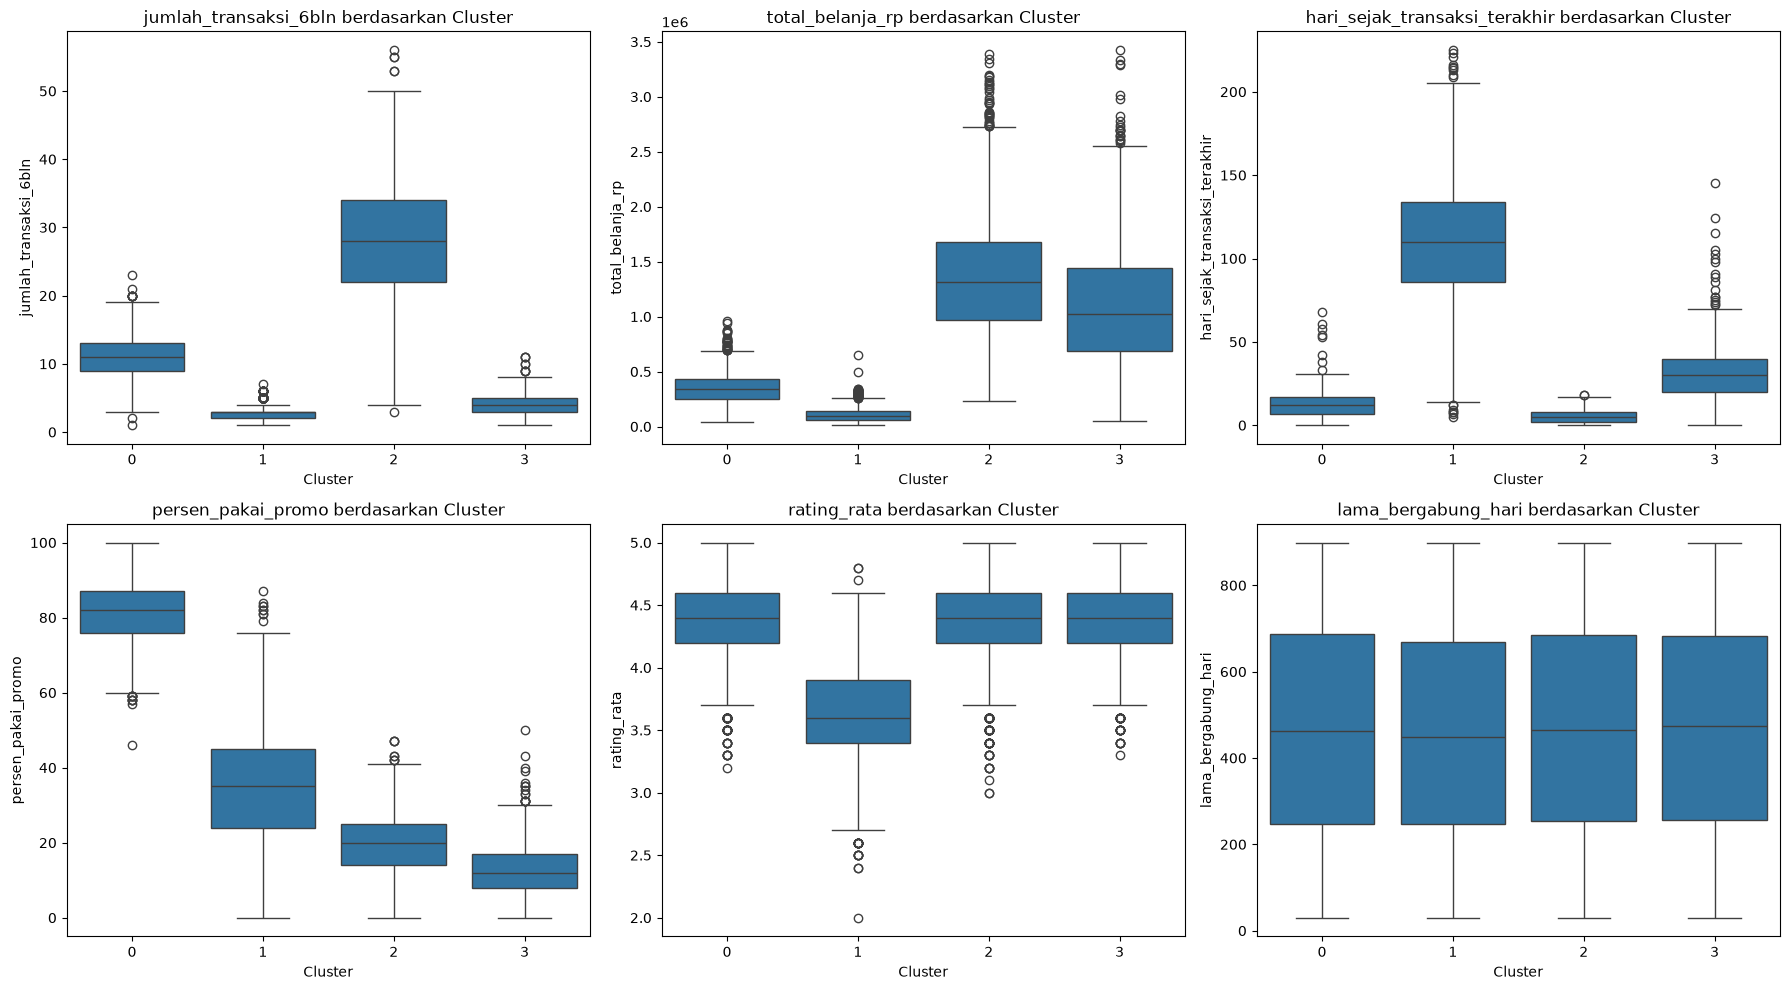

In [ ]:
# Visualisasi karakteristik setiap cluster
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

kolom_visualisasi = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

for kolom, ax in zip(kolom_visualisasi, axes.flatten()):
    sns.boxplot(
        data=df_segmentasi_final,
        x="cluster",
        y=kolom,
        ax=ax
    )

    ax.set_title(f"{kolom} berdasarkan Cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.savefig(
    "../reports/figures/karakteristik_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Rekomendasi promosi final

Cluster	Nama segmen	Karakteristik utama	Rekomendasi promosi
0	Promo-Responsive Active Customers	2.497 pelanggan (24,97%). Transaksi rata-rata 10,93 kali, belanja Rp348.541, terakhir bertransaksi 12 hari lalu, penggunaan promo 81,54%. Banyak menggunakan GoFood (31%) dan menyukai roti (42,89%) serta kopi (41,85%).	Tawarkan bundling roti dan kopi, voucher pembelian berikutnya, serta program stamp/poin. Mereka relatif aktif dan sangat responsif terhadap promo.
1	Inactive / At-Risk Customers	2.966 pelanggan (29,66%). Transaksi rata-rata hanya 2,56 kali, belanja Rp107.158, terakhir bertransaksi 109,61 hari lalu, rating 3,64. Penggunaan promo 34,64%.	Jalankan kampanye win-back berupa voucher kembali berbelanja, penawaran produk favorit, dan survei kepuasan. Prioritaskan pelanggan yang sudah lama tidak bertransaksi.
2	High-Value Loyal Customers	3.023 pelanggan (30,23%). Transaksi rata-rata 27,88 kali, belanja Rp1.353.954, terakhir bertransaksi 5,15 hari lalu, rating 4,38. Penggunaan promo hanya 19,66%. Mayoritas menggunakan toko (68,54%) dan menyukai kopi (54,12%).	Berikan program VIP/loyalty rewards, akses menu baru, hadiah apresiasi, dan penawaran eksklusif. Hindari terlalu mengandalkan diskon karena kelompok ini sudah aktif dan memiliki nilai belanja tinggi.
3	Occasional High-Spenders	1.514 pelanggan (15,14%). Transaksi rata-rata 4,10 kali, belanja Rp1.093.769, terakhir bertransaksi 30,66 hari lalu, rating 4,38. Penggunaan promo hanya 12,56%. Mayoritas menyukai kue ulang tahun (42,27%) dan paket snack (40,95%).	Tawarkan paket kue ulang tahun dan snack untuk acara, layanan pre-order, pengingat pemesanan, serta rekomendasi produk premium.

Mengapa rekomendasi ini sesuai dengan hasil analisis?
- Cluster 0: penggunaan promo paling tinggi, sehingga promosi bundling dan voucher relevan untuk mempertahankan frekuensi pembelian.
- Cluster 1: frekuensi transaksi paling rendah, jarak transaksi terakhir paling lama, dan rating paling rendah. Ini kelompok yang perlu diaktifkan kembali.
- Cluster 2: transaksi paling sering, nilai belanja tertinggi, dan jarak transaksi terakhir paling pendek. Strateginya mempertahankan loyalitas, bukan memberikan diskon besar-besaran.
- Cluster 3: jumlah transaksi relatif sedikit, tetapi nilai belanja cukup tinggi. Komposisi produk favoritnya juga sangat menonjol pada kue ulang tahun dan paket snack, sehingga promosi berbasis kebutuhan acara lebih tepat.

Catatan interpretasi: kecamatan dan metode pembayaran tidak menunjukkan perbedaan yang kuat antarkelompok. Distribusi kecamatan relatif merata, sementara persentase metode pembayaran hampir serupa. Jadi, jangan menjadikan kecamatan atau metode pembayaran sebagai dasar utama strategi segmentasi.

# Menyimpan hasil segmentasi final

In [99]:
from pathlib import Path

# Membuat folder untuk menyimpan hasil
folder_output = Path("../data/processed")
folder_output.mkdir(parents=True, exist_ok=True)

# Simpan data pelanggan beserta label cluster
df_segmentasi_final.to_csv(
    folder_output / "hasil_segmentasi_model4.csv",
    index=False
)

print("Hasil segmentasi berhasil disimpan!")
print("Jumlah data:", len(df_segmentasi_final))

Hasil segmentasi berhasil disimpan!
Jumlah data: 10000


In [100]:
# Menyimpan tabel profil untuk laporan
# Simpan distribusi cluster
distribusi_final.to_csv(
    folder_output / "distribusi_cluster_model4.csv"
)

# Simpan profil numerik
profil_final.to_csv(
    folder_output / "profil_numerik_model4.csv"
)

# Simpan profil kategorikal
for kolom in kolom_kategori:
    tabel = pd.crosstab(
        df_segmentasi_final["cluster"],
        df_segmentasi_final[kolom],
        normalize="index"
    ) * 100

    tabel.round(2).to_csv(
        folder_output / f"profil_{kolom}_model4.csv"
    )

print("Seluruh tabel profil berhasil disimpan!")

Seluruh tabel profil berhasil disimpan!


In [101]:
# Memeriksa objek model dan scaler

# Mencari variabel yang berkaitan dengan model, scaler,
# dan fitur Model 4 di notebook

kata_kunci = ["model", "kmeans", "scaler", "fitur", "X_model"]

variabel_terkait = [
    nama for nama in globals()
    if any(kunci in nama.lower() for kunci in kata_kunci)
]

for nama in sorted(variabel_terkait):
    objek = globals()[nama]
    print(f"{nama} : {type(objek).__name__}")

KMeans : ABCMeta
StandardScaler : type
data_model : dict
df_fitur : DataFrame
df_fitur_baru : DataFrame
df_model : DataFrame
df_model_baru : DataFrame
df_perbandingan_model : DataFrame
df_segmentasi_model4 : DataFrame
fitur_cat : list
fitur_kategorikal : list
fitur_num : list
fitur_numerik : list
hasil_model_final : dict
hasil_semua_model : list
kmeans : KMeans
konfigurasi_model : dict
model_final : KMeans
model_kandidat : dict
model_terpilih : str
nama_model : str
profil_kategori_model4 : DataFrame
profil_model4 : DataFrame
scaler : StandardScaler
scaler_baru : StandardScaler
skor_model : list


In [102]:
# Memeriksa model final dan scaler
print("===== MODEL FINAL =====")
print("Tipe model:", type(model_final).__name__)
print("Jumlah cluster:", model_final.n_clusters)
print("Jumlah fitur:", model_final.n_features_in_)

print("\n===== SCALER =====")
print("Tipe scaler:", type(scaler).__name__)

print("\nRata-rata fitur saat scaling:")
print(scaler.mean_)

print("\nStandar deviasi fitur:")
print(scaler.scale_)

print("\n===== FITUR MODEL =====")
print("fitur_num:", fitur_num)
print("fitur_numerik:", fitur_numerik)

print("\n===== MODEL TERPILIH =====")
print(model_terpilih)

===== MODEL FINAL =====
Tipe model: KMeans
Jumlah cluster: 10
Jumlah fitur: 29

===== SCALER =====
Tipe scaler: StandardScaler

Rata-rata fitur saat scaling:
[  2.21158177  12.8819769    2.93972041  38.4808       4.15743
 463.2593    ]

Standar deviasi fitur:
[  0.91496039   1.18760822   1.40781871  28.01917971   0.50339924
 250.81215454]

===== FITUR MODEL =====
fitur_num: ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari']
fitur_numerik: ['umur', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari']

===== MODEL TERPILIH =====
Model 4


In [103]:
# Memeriksa struktur hasil model final
print("===== HASIL MODEL FINAL =====")

if isinstance(hasil_model_final, dict):
    for key, value in hasil_model_final.items():
        print(f"\n{key}:")
        print("Tipe:", type(value).__name__)

        if isinstance(value, (list, tuple)):
            print("Isi:", value)

        elif isinstance(value, dict):
            print("Isi:", value)

        elif isinstance(value, pd.DataFrame):
            print(value.head())

        elif hasattr(value, "n_clusters"):
            print("Jumlah cluster:", value.n_clusters)

        else:
            print(value)

else:
    print(hasil_model_final)

===== HASIL MODEL FINAL =====

K:
Tipe: int
4

model:
Tipe: KMeans
Jumlah cluster: 4

labels:
Tipe: ndarray
[2 2 0 ... 1 1 1]

score_full:
Tipe: float
0.36963515253834667


In [105]:
# Memperbaiki objek model final

# Ambil model K-Means dari hasil eksperimen terpilih
model_final = hasil_model_final["model"]

# Ambil label hasil clustering Model 4
label_final = hasil_model_final["labels"]

# Periksa model
print("===== MODEL FINAL SETELAH DIPERBAIKI =====")
print("Model terpilih:", model_terpilih)
print("Jumlah cluster:", model_final.n_clusters)
print("Jumlah fitur:", model_final.n_features_in_)
print("Silhouette Score:", hasil_model_final["score_full"])
print("Jumlah label:", len(label_final))

===== MODEL FINAL SETELAH DIPERBAIKI =====
Model terpilih: Model 4
Jumlah cluster: 4
Jumlah fitur: 6
Silhouette Score: 0.36963515253834667
Jumlah label: 10000


In [106]:
# Memastikan scaler dan urutan fitur sesuai
fitur_final = [
    "jumlah_transaksi_6bln",
    "total_belanja_rp",
    "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo",
    "rating_rata",
    "lama_bergabung_hari"
]

In [107]:
# Memeriksa scaler Model 4
print("===== PEMERIKSAAN SCALER =====")

print("Jumlah fitur scaler:", scaler.n_features_in_)
print("Jumlah fitur Model 4:", len(fitur_final))

print("\nUrutan fitur:")
print(fitur_final)

print("\nJumlah rata-rata scaler:", len(scaler.mean_))
print("Jumlah standar deviasi scaler:", len(scaler.scale_))

# Validasi
assert model_final.n_clusters == 4
assert model_final.n_features_in_ == 6
assert scaler.n_features_in_ == 6
assert len(fitur_final) == 6

print("\nModel dan scaler memiliki jumlah fitur yang sesuai.")

===== PEMERIKSAAN SCALER =====
Jumlah fitur scaler: 6
Jumlah fitur Model 4: 6

Urutan fitur:
['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari']

Jumlah rata-rata scaler: 6
Jumlah standar deviasi scaler: 6

Model dan scaler memiliki jumlah fitur yang sesuai.


# Memeriksa preprocessing yang digunakan Model 4

In [108]:
# Memeriksa data input Model 4
print("===== STRUKTUR DATA MODEL =====")

print("df_model:")
print("Shape:", df_model.shape)
print("Kolom:", df_model.columns.tolist())

print("\ndf_fitur:")
print("Shape:", df_fitur.shape)
print("Kolom:", df_fitur.columns.tolist())

print("\n===== STRUKTUR DATA MODEL BARU =====")

print("df_model_baru:")
print("Shape:", df_model_baru.shape)
print("Kolom:", df_model_baru.columns.tolist())

print("\n===== INFORMASI DATA MODEL =====")

print("data_model:")
if isinstance(data_model, dict):
    for key, value in data_model.items():
        print(
            key,
            "=>",
            type(value).__name__,
            getattr(value, "shape", "")
        )
else:
    print(type(data_model).__name__)

===== STRUKTUR DATA MODEL =====
df_model:
Shape: (10000, 29)
Kolom: ['umur', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari', 'kecamatan_Antapani', 'kecamatan_Arcamanik', 'kecamatan_Bandung Wetan', 'kecamatan_Buahbatu', 'kecamatan_Cibeunying Kidul', 'kecamatan_Cidadap', 'kecamatan_Coblong', 'kecamatan_Lengkong', 'kecamatan_Sukajadi', 'kecamatan_Sumur Bandung', 'channel_utama_gofood', 'channel_utama_grabfood', 'channel_utama_shopeefood', 'channel_utama_toko', 'metode_bayar_ewallet', 'metode_bayar_qris', 'metode_bayar_transfer', 'metode_bayar_tunai', 'kategori_favorit_kopi', 'kategori_favorit_kue_ulang_tahun', 'kategori_favorit_paket_snack', 'kategori_favorit_roti']

df_fitur:
Shape: (10000, 11)
Kolom: ['umur', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari', 'kecamatan', 'channel_utama', 'metode_bayar', 'kategor

In [109]:
# Memeriksa konfigurasi empat model
for nama, info in data_model.items():

    print(f"\n{'='*50}")
    print(nama)
    print("="*50)

    for key, value in info.items():

        print(f"\n{key}:")
        print("Tipe:", type(value).__name__)

        if isinstance(value, pd.DataFrame):
            print("Shape:", value.shape)
            print("Kolom:", value.columns.tolist())

        elif isinstance(value, (list, tuple)):
            print("Isi:", value)

        elif isinstance(value, dict):
            print("Keys:", list(value.keys()))

        elif hasattr(value, "n_clusters"):
            print("Jumlah cluster:", value.n_clusters)
            print("Jumlah fitur:", value.n_features_in_)

        elif hasattr(value, "n_features_in_"):
            print("Jumlah fitur:", value.n_features_in_)

        elif hasattr(value, "shape"):
            print("Shape:", value.shape)

        else:
            print(value)


Model 1

X:
Tipe: ndarray
Shape: (10000, 29)

scaler:
Tipe: StandardScaler
Jumlah fitur: 29

kolom_fitur:
Tipe: list
Isi: ['umur', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari', 'kecamatan_Antapani', 'kecamatan_Arcamanik', 'kecamatan_Bandung Wetan', 'kecamatan_Buahbatu', 'kecamatan_Cibeunying Kidul', 'kecamatan_Cidadap', 'kecamatan_Coblong', 'kecamatan_Lengkong', 'kecamatan_Sukajadi', 'kecamatan_Sumur Bandung', 'channel_utama_gofood', 'channel_utama_grabfood', 'channel_utama_shopeefood', 'channel_utama_toko', 'metode_bayar_ewallet', 'metode_bayar_qris', 'metode_bayar_transfer', 'metode_bayar_tunai', 'kategori_favorit_kopi', 'kategori_favorit_kue_ulang_tahun', 'kategori_favorit_paket_snack', 'kategori_favorit_roti']

Model 2

X:
Tipe: ndarray
Shape: (10000, 19)

scaler:
Tipe: StandardScaler
Jumlah fitur: 19

kolom_fitur:
Tipe: list
Isi: ['umur', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_

In [110]:
# Memeriksa konsistensi hasil clustering
print("===== MODEL FINAL =====")
print("K:", model_final.n_clusters)
print("Fitur:", model_final.n_features_in_)

print("\n===== LABEL MODEL FINAL =====")
print("Jumlah label:", len(label_final))
print("Jumlah cluster unik:", len(np.unique(label_final)))
print("Label unik:", np.unique(label_final))

print("\n===== DATA SEGMENTASI MODEL 4 =====")
print("Shape:", df_segmentasi_model4.shape)
print("Kolom:", df_segmentasi_model4.columns.tolist())

print("\n===== DISTRIBUSI LABEL MODEL FINAL =====")
print(pd.Series(label_final).value_counts().sort_index())

if "cluster" in df_segmentasi_model4.columns:
    print("\n===== DISTRIBUSI CLUSTER DATA MODEL 4 =====")
    print(
        df_segmentasi_model4["cluster"]
        .value_counts()
        .sort_index()
    )

===== MODEL FINAL =====
K: 4
Fitur: 6

===== LABEL MODEL FINAL =====
Jumlah label: 10000
Jumlah cluster unik: 4
Label unik: [0 1 2 3]

===== DATA SEGMENTASI MODEL 4 =====
Shape: (10000, 14)
Kolom: ['id_pelanggan', 'tanggal_daftar', 'umur', 'kecamatan', 'channel_utama', 'metode_bayar', 'kategori_favorit', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari', 'cluster']

===== DISTRIBUSI LABEL MODEL FINAL =====
0    2497
1    2966
2    3023
3    1514
Name: count, dtype: int64

===== DISTRIBUSI CLUSTER DATA MODEL 4 =====
cluster
0    2497
1    2966
2    3023
3    1514
Name: count, dtype: int64


In [112]:
# Memastikan model final benar-benar Model 4

# Mengambil data dan scaler khusus Model 4
X_model4 = data_model["Model 4"]["X"]
scaler_model4 = data_model["Model 4"]["scaler"]
fitur_model4 = data_model["Model 4"]["kolom_fitur"]

# Prediksi ulang menggunakan model final
label_cek = model_final.predict(X_model4)

print("===== VALIDASI MODEL FINAL =====")

print("Jumlah fitur Model 4:", X_model4.shape[1])
print("Jumlah fitur K-Means:", model_final.n_features_in_)
print("Jumlah fitur scaler:", scaler_model4.n_features_in_)

print("\nApakah prediksi sama dengan label sebelumnya?")
print(np.array_equal(label_cek, label_final))

print("\nApakah prediksi sama dengan cluster di dataframe?")
print(
    np.array_equal(
        label_cek,
        df_segmentasi_model4["cluster"].to_numpy()
    )
)

print("\n===== DISTRIBUSI HASIL PREDIKSI ULANG =====")
print(pd.Series(label_cek).value_counts().sort_index())

===== VALIDASI MODEL FINAL =====
Jumlah fitur Model 4: 6
Jumlah fitur K-Means: 6
Jumlah fitur scaler: 6

Apakah prediksi sama dengan label sebelumnya?
True

Apakah prediksi sama dengan cluster di dataframe?
True

===== DISTRIBUSI HASIL PREDIKSI ULANG =====
0    2497
1    2966
2    3023
3    1514
Name: count, dtype: int64


In [113]:
# Menetapkan objek khusus untuk deployment Model 4

X_final = data_model["Model 4"]["X"]

scaler_final = data_model["Model 4"]["scaler"]

fitur_final = data_model["Model 4"]["kolom_fitur"]

kmeans_final = model_final

label_final = kmeans_final.predict(X_final)

# Memastikan konfigurasi
print("===== KONFIGURASI MODEL FINAL =====")

print("Algoritma:", type(kmeans_final).__name__)
print("Jumlah cluster:", kmeans_final.n_clusters)
print("Jumlah fitur:", len(fitur_final))
print("Fitur yang digunakan:")

for i, fitur in enumerate(fitur_final, start=1):
    print(f"{i}. {fitur}")

print("\nJumlah pelanggan:", len(label_final))
print("Silhouette Score:", round(hasil_model_final["score_full"], 6))

===== KONFIGURASI MODEL FINAL =====
Algoritma: KMeans
Jumlah cluster: 4
Jumlah fitur: 6
Fitur yang digunakan:
1. jumlah_transaksi_6bln
2. total_belanja_rp
3. hari_sejak_transaksi_terakhir
4. persen_pakai_promo
5. rating_rata
6. lama_bergabung_hari

Jumlah pelanggan: 10000
Silhouette Score: 0.369635


# Menyimpan model final

In [114]:
# Menyimpan model final
import joblib
from pathlib import Path

# Membuat folder models
folder_models = Path("../models")
folder_models.mkdir(parents=True, exist_ok=True)

# Menggabungkan model, scaler, dan metadata
paket_model = {
    "model": kmeans_final,
    "scaler": scaler_final,
    "fitur": fitur_final,
    "nama_model": "Model 4",
    "algoritma": "KMeans",
    "jumlah_cluster": 4,
    "silhouette_score": hasil_model_final["score_full"]
}

# Menyimpan seluruh komponen dalam satu file
joblib.dump(
    paket_model,
    folder_models / "model_final.joblib"
)

print("Model final berhasil disimpan!")
print("Lokasi:", folder_models / "model_final.joblib")

Model final berhasil disimpan!
Lokasi: ..\models\model_final.joblib


In [115]:
# Menguji apakah model berhasil dimuat kembali
# Memuat model dari file
paket_model_loaded = joblib.load(
    folder_models / "model_final.joblib"
)

# Mengambil komponen model
model_loaded = paket_model_loaded["model"]
scaler_loaded = paket_model_loaded["scaler"]
fitur_loaded = paket_model_loaded["fitur"]

print("===== HASIL PEMUATAN MODEL =====")
print("Nama model:", paket_model_loaded["nama_model"])
print("Algoritma:", paket_model_loaded["algoritma"])
print("Jumlah cluster:", model_loaded.n_clusters)
print("Jumlah fitur:", model_loaded.n_features_in_)
print("Fitur:", fitur_loaded)
print("Silhouette Score:", paket_model_loaded["silhouette_score"])

# Uji prediksi ulang
prediksi_loaded = model_loaded.predict(X_final)

print("\nApakah hasil prediksi tetap sama?")
print(np.array_equal(prediksi_loaded, label_final))

===== HASIL PEMUATAN MODEL =====
Nama model: Model 4
Algoritma: KMeans
Jumlah cluster: 4
Jumlah fitur: 6
Fitur: ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata', 'lama_bergabung_hari']
Silhouette Score: 0.36963515253834667

Apakah hasil prediksi tetap sama?
True


In [116]:
# Memuat ulang dan menguji model
# Memuat ulang model dari file
import joblib
from pathlib import Path
import numpy as np

folder_models = Path("../models")

paket_model_loaded = joblib.load(
    folder_models / "model_final.joblib"
)

# Mengambil komponen model
model_loaded = paket_model_loaded["model"]
scaler_loaded = paket_model_loaded["scaler"]
fitur_loaded = paket_model_loaded["fitur"]

# Menguji prediksi menggunakan data Model 4
X_cek = data_model["Model 4"]["X"]

prediksi_cek = model_loaded.predict(X_cek)

# Memeriksa kesesuaian hasil
print("Nama model:", paket_model_loaded["nama_model"])
print("Algoritma:", paket_model_loaded["algoritma"])
print("Jumlah cluster:", paket_model_loaded["jumlah_cluster"])
print("Jumlah fitur:", len(fitur_loaded))
print("Silhouette Score:", paket_model_loaded["silhouette_score"])

print(
    "Hasil prediksi sama dengan label final:",
    np.array_equal(prediksi_cek, label_final)
)

Nama model: Model 4
Algoritma: KMeans
Jumlah cluster: 4
Jumlah fitur: 6
Silhouette Score: 0.36963515253834667
Hasil prediksi sama dengan label final: True


# # Membuat funsi prediksi pelanggan baru

In [117]:
# Fungsi prediksi_cluster
def prediksi_cluster(data_pelanggan):
    # Memastikan urutan fitur sama dengan saat training
    data_fitur = data_pelanggan[fitur_loaded].copy()

    # Menggunakan scaler dari model final
    data_scaled = scaler_loaded.transform(data_fitur)

    # Memprediksi cluster
    hasil_prediksi = model_loaded.predict(data_scaled)

    return hasil_prediksi

In [118]:
# Menguji fungsi prediksi
# Mengambil satu data pelanggan
data_uji = df_clean[fitur_loaded].iloc[[0]]

# Melakukan prediksi
hasil_uji = prediksi_cluster(data_uji)

print("Data pelanggan yang diuji:")
display(data_uji)

print("Hasil prediksi cluster:", hasil_uji[0])

Data pelanggan yang diuji:


,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata,lama_bergabung_hari
0,27,1480300,0,17,4.2,305


Hasil prediksi cluster: 2


In [119]:
# Fungsi prediksi pelanggan baru
def prediksi_pelanggan_baru(
    jumlah_transaksi_6bln,
    total_belanja_rp,
    hari_sejak_transaksi_terakhir,
    persen_pakai_promo,
    rating_rata,
    tanggal_daftar
):
    # Tanggal acuan harus sama dengan saat feature engineering
    tanggal_acuan = pd.Timestamp("2026-06-30")

    # Menghitung lama bergabung
    tanggal_daftar = pd.to_datetime(tanggal_daftar)
    lama_bergabung_hari = (
        tanggal_acuan - tanggal_daftar
    ).days

    # Menyusun data sesuai fitur Model 4
    data_baru = pd.DataFrame([{
        "jumlah_transaksi_6bln": jumlah_transaksi_6bln,
        "total_belanja_rp": total_belanja_rp,
        "hari_sejak_transaksi_terakhir": hari_sejak_transaksi_terakhir,
        "persen_pakai_promo": persen_pakai_promo,
        "rating_rata": rating_rata,
        "lama_bergabung_hari": lama_bergabung_hari
    }])

    # Menyesuaikan urutan fitur
    data_baru = data_baru[fitur_loaded]

    # Scaling dan prediksi
    data_scaled = scaler_loaded.transform(data_baru)
    hasil_cluster = model_loaded.predict(data_scaled)

    return hasil_cluster[0]

In [120]:
# Menguji pelanggan baru
hasil_pelanggan_baru = prediksi_pelanggan_baru(
    jumlah_transaksi_6bln=15,
    total_belanja_rp=750000,
    hari_sejak_transaksi_terakhir=10,
    persen_pakai_promo=25,
    rating_rata=4.5,
    tanggal_daftar="2025-09-01"
)

print("Hasil prediksi pelanggan baru:")
print("Cluster:", hasil_pelanggan_baru)

Hasil prediksi pelanggan baru:
Cluster: 2


In [121]:
# Membuat pemetaan nama cluster
# Pemetaan cluster berdasarkan hasil analisis profil
nama_segmen = {
    0: "Pelanggan Aktif dan Responsif terhadap Promo",
    1: "Pelanggan Tidak Aktif / Berisiko Churn",
    2: "Pelanggan Loyal Bernilai Tinggi",
    3: "Pelanggan Sesekali dengan Belanja Tinggi"
}

# Deskripsi dan rekomendasi bisnis setiap segmen
deskripsi_segmen = {
    0: {
        "karakteristik": "Sering bertransaksi dan memiliki penggunaan promo yang tinggi.",
        "rekomendasi": "Berikan voucher pembelian berikutnya, promo bundling roti dan kopi, serta program loyalty stamp."
    },
    1: {
        "karakteristik": "Frekuensi transaksi rendah dan sudah cukup lama tidak bertransaksi.",
        "rekomendasi": "Lakukan kampanye win-back, berikan penawaran produk favorit, dan kirim survei kepuasan."
    },
    2: {
        "karakteristik": "Memiliki frekuensi transaksi dan total belanja tinggi serta relatif aktif.",
        "rekomendasi": "Berikan reward VIP, akses awal menu baru, dan apresiasi pelanggan tanpa terlalu bergantung pada diskon."
    },
    3: {
        "karakteristik": "Frekuensi transaksi relatif rendah, tetapi nilai belanjanya tinggi.",
        "rekomendasi": "Tawarkan paket premium, kue ulang tahun, snack pack, dan pengingat pre-order."
    }
}

print("Pemetaan segmen berhasil dibuat!")

Pemetaan segmen berhasil dibuat!


In [ ]:
# Menguji hasil prediksi dengan nama segmen
# Mengubah hasil prediksi menjadi informasi bisnis
cluster_prediksi = hasil_pelanggan_baru

print("Hasil Segmentasi Pelanggan Baru")
print("=" * 45)
print("Nomor Cluster:", cluster_prediksi)
print("Nama Segmen:", nama_segmen[cluster_prediksi])
print(
    "Karakteristik:",
    deskripsi_segmen[cluster_prediksi]["karakteristik"]
)
print(
    "Rekomendasi:",
    deskripsi_segmen[cluster_prediksi]["rekomendasi"]
)

Hasil Segmentasi Pelanggan Baru
Nomor Cluster: 2
Nama Segmen: Pelanggan Loyal Bernilai Tinggi
Karakteristik: Memiliki frekuensi transaksi dan total belanja tinggi serta relatif aktif.
Rekomendasi: Berikan reward VIP, akses awal menu baru, dan apresiasi pelanggan tanpa terlalu bergantung pada diskon.
